# Fuel Inventory Management Project

## Executive summary

**1. Current inventory management.** Most deliveries are too small to earn quantity discounts: 88.8% of invoices received none, and total discount savings were CAD 205,979.41. Station 1 needs the most attention, especially gasoline, where inventory was below seven days of estimated demand in 69.7% of complete observed hours. No zero readings were recorded, but reserve coverage could be improved.

**2. Improved ordering strategies.** Order when each station/fuel group reaches its seven-day reserve, using the smallest tested quantity that earns the best feasible discount. All 16 groups have room to replenish at that level. Using the same historical purchase volume, the policy increases modeled discount savings to CAD 868,262.43—an additional **CAD 662,283.03 over the observed period**. These estimates assume continuous monitoring and immediate delivery.

**3. Weekday purchasing.** Saturday has the lowest overall average prices, but only 13 invoices were issued that day. Comparisons within the same station, fuel type, and month give mixed results, so there is no firm basis for a Saturday-only policy or an additional savings forecast. A weekly delivery cycle fits 14 of the 16 station/fuel groups at average demand; Station 1 needs more frequent deliveries. Keep the reserve ahead of any weekday preference.

**4. Tank replacement.** No single-tank replacement pays for itself within five years at the baseline CAD 250,000 cost and current demand. Station 1 gasoline is the closest case, with about CAD 41,487 in annual additional discount savings and a 6.03-year simple payback. Improve ordering first; reconsider replacement if costs fall or higher demand changes the attainable discount. These benefits are incremental to improved ordering, rather than savings to count twice.

## Project and setup

Analyze purchasing and inventory records to evaluate current replenishment, improve ordering, compare weekdays, and assess tank replacement. Quantities are in liters and costs are in Canadian dollars (CAD).

Place `Locations-1.csv`, `Tanks-1.csv`, `Invoices-1.csv`, `Fuel_Level_Part_1-1.csv`, and `Fuel_Level_Part_2-1.csv` beside this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

locations = pd.read_csv("Locations-1.csv")
tanks = pd.read_csv("Tanks-1.csv")
invoices = pd.read_csv("Invoices-1.csv")
fuel_part_1 = pd.read_csv("Fuel_Level_Part_1-1.csv")
fuel_part_2 = pd.read_csv("Fuel_Level_Part_2-1.csv")

## Exploratory Data Analysis

First, look through all five datasets before answering the business questions. Check their structure, missing values, duplicates, identifiers, fuel labels, and numerical ranges.


In [2]:
# match the column names and combine the files
fuel_part_1 = fuel_part_1.rename(columns={"Fuel Level": "Fuel_Level", "Time stamp": "Timestamp"})
fuel_levels = pd.concat([fuel_part_1, fuel_part_2], ignore_index=True)

# convert timestamps and invoice dates
fuel_levels["Timestamp"] = pd.to_datetime(fuel_levels["Timestamp"], errors="coerce")
invoices["Invoice Date"] = pd.to_datetime(invoices["Invoice Date"], errors="coerce")

# check structure, missing values, and duplicate records
for name, data in [("Locations", locations), ("Tanks", tanks), ("Invoices", invoices), ("Fuel levels", fuel_levels)]:
    print(name)
    print("Rows and columns:", data.shape)
    print(data.dtypes)
    print("Missing values:")
    print(data.isna().sum())
    print("Exact duplicates:", data.duplicated().sum())

# check identifiers and fuel labels
print("Tank IDs:", tanks["Tank ID"].unique())
print("Reading tank IDs:", fuel_levels["Tank ID"].unique())
print("Tank types:", tanks["Tank Type"].unique())
print("Invoice fuel types:", invoices["Fuel Type"].unique())
print("Unmatched reading IDs:", (~fuel_levels["Tank ID"].isin(tanks["Tank ID"])).sum())
print("Duplicate station IDs:", locations.duplicated(subset=["Gas Station Location"]).sum())
print("Duplicate tank IDs:", tanks.duplicated(subset=["Tank ID"]).sum())
print("Duplicate known invoice IDs:", invoices.dropna(subset=["Invoice ID"]).duplicated(subset=["Invoice ID"]).sum())
display(tanks.groupby("Tank Type")["Tank Capacity"].agg(["count", "min", "max"]))
display(invoices[["Amount Purchased", "Gross Purchase Cost"]].describe())


Locations
Rows and columns: (8, 5)
Gas Station Location       int64
Gas Station Name          object
Gas Station Address       object
Gas Station Latitude     float64
Gas Station Longitude    float64
dtype: object
Missing values:
Gas Station Location     0
Gas Station Name         0
Gas Station Address      0
Gas Station Latitude     0
Gas Station Longitude    0
dtype: int64
Exact duplicates: 0
Tanks
Rows and columns: (23, 5)
Tank ID          object
Tank Location     int64
Tank Number       int64
Tank Type        object
Tank Capacity     int64
dtype: object
Missing values:
Tank ID          0
Tank Location    0
Tank Number      0
Tank Type        0
Tank Capacity    0
dtype: int64
Exact duplicates: 0
Invoices
Rows and columns: (2873, 6)
Invoice Date                    datetime64[ns]
Invoice ID                             float64
Invoice Gas Station Location             int64
Gross Purchase Cost                    float64
Amount Purchased                       float64
Fuel Type           

,count,min,max
Tank Type,,,
D,10,5000,70000
P,1,40000,40000
U,12,5000,70000


,Amount Purchased,Gross Purchase Cost
count,2831.000000,2831.000000
mean,10270.822347,11762.178117
std,6101.906255,6562.632861
min,96.976000,94.635250
25%,7073.384000,8327.902000
50%,9262.304000,10459.087830
75%,11435.984000,12518.350870
max,33826.560000,33118.552090


## Question I — Evaluate Current Inventory Management

Prepare and link the records, assess inventory availability and replenishment patterns, estimate consumption, and evaluate current supplier deliveries.

### Data preparation and linking

Remove incomplete records and exact duplicates, average conflicting readings, and match fuel labels using the instructor's clarification. Link readings to tank and station details, then link invoices to capacities grouped by station and fuel type. Check quantities and confirm that joins preserve the number of records.


In [3]:
# drop rows missing the values we need
invoices = invoices.dropna(subset=["Gross Purchase Cost", "Amount Purchased", "Fuel Type"])

fuel_levels = fuel_levels.dropna(subset=["Fuel_Level"])



fuel_levels = fuel_levels.drop_duplicates()

# leave out premium and match the invoice fuel labels
tanks = tanks.loc[tanks["Tank Type"] != "P"].copy()
tanks["Tank Type"] = tanks["Tank Type"].replace({"U": "G"})

# keep readings for the tanks we are using
fuel_levels = fuel_levels.loc[fuel_levels["Tank ID"].isin(tanks["Tank ID"])].copy()



# average conflicting readings for each tank and timestamp
fuel_levels = fuel_levels.groupby(["Tank ID", "Timestamp"], as_index=False)["Fuel_Level"].mean()



# link fuel readings to tank details
fuel_merged = pd.merge(fuel_levels, tanks, on="Tank ID", how="left")

# check for fuel levels that do not make sense
print("Negative fuel levels:", (fuel_merged["Fuel_Level"] < 0).sum())

print("Fuel levels above capacity:", (fuel_merged["Fuel_Level"] > fuel_merged["Tank Capacity"]).sum())

print("Nonpositive tank capacities:", (tanks["Tank Capacity"] <= 0).sum())

# check for zero or negative delivery quantities and costs
print("Nonpositive purchase quantities:", (invoices["Amount Purchased"] <= 0).sum())

print("Nonpositive purchase costs:", (invoices["Gross Purchase Cost"] <= 0).sum())



# match the station identifier column name
station_details = locations.rename(columns={"Gas Station Location": "Tank Location"})

# link fuel readings to station details
fuel_merged = pd.merge(fuel_merged, station_details, on="Tank Location", how="left")



# check the merges
print("Cleaned fuel readings:", fuel_levels.shape[0])
print("Merged fuel readings:", fuel_merged.shape[0])

print("\nMissing tank or station details:")
print(fuel_merged[["Tank Location", "Tank Type", "Tank Capacity", "Gas Station Name"]].isna().sum())

# total capacity by station and fuel type
capacity_summary = tanks.groupby(["Tank Location", "Tank Type"], as_index=False)["Tank Capacity"].sum()

# match the invoice column names
capacity_summary = capacity_summary.rename(columns={"Tank Location": "Invoice Gas Station Location", "Tank Type": "Fuel Type"})

display(capacity_summary)

# link invoices to total capacity by station and fuel type
invoice_merged = pd.merge(invoices, capacity_summary, on=["Invoice Gas Station Location", "Fuel Type"], how="left")

# add the station columns used in questions 3 and 4
invoice_station_details = locations.copy()
invoice_station_details["Invoice Gas Station Location"] = invoice_station_details["Gas Station Location"]
invoice_merged = pd.merge(
    invoice_merged, invoice_station_details,
    on="Invoice Gas Station Location", how="left"
)

# check the merge
print("Original invoices:", invoices.shape[0])
print("Merged invoices:", invoice_merged.shape[0])
print("Missing capacities:", invoice_merged["Tank Capacity"].isna().sum())
print("Missing station details:", invoice_merged["Gas Station Name"].isna().sum())

# check purchase quantities against total capacity
print("Purchases above total capacity:", (invoice_merged["Amount Purchased"] > invoice_merged["Tank Capacity"]).sum())

Negative fuel levels: 0
Fuel levels above capacity: 0
Nonpositive tank capacities: 0
Nonpositive purchase quantities: 0
Nonpositive purchase costs: 0
Cleaned fuel readings: 1775798
Merged fuel readings: 1775798

Missing tank or station details:
Tank Location       0
Tank Type           0
Tank Capacity       0
Gas Station Name    0
dtype: int64


,Invoice Gas Station Location,Fuel Type,Tank Capacity
0,1,D,80000
1,1,G,120000
2,2,D,110000
3,2,G,110000
4,3,D,30000
5,3,G,30000
6,4,D,40000
7,4,G,40000
8,5,D,25000
9,5,G,25000


Original invoices: 2831
Merged invoices: 2831
Missing capacities: 0
Missing station details: 0
Purchases above total capacity: 0


### Inventory changes and reporting gaps

Sort readings within each tank and calculate changes in fuel level and elapsed time. Check the usual reporting intervals and the longest gaps.


In [4]:
# sort readings before calculating changes
fuel_merged = fuel_merged.sort_values(["Tank ID", "Timestamp"])

# work out inventory changes within each tank
fuel_merged["Fuel_Change"] = fuel_merged.groupby("Tank ID")["Fuel_Level"].diff()

fuel_merged[["Tank ID", "Timestamp", "Fuel_Level", "Fuel_Change"]].head(10)

# work out time between readings within each tank
fuel_merged["Time_Change"] = fuel_merged.groupby("Tank ID")["Timestamp"].diff()

fuel_merged[["Tank ID", "Timestamp", "Fuel_Change", "Time_Change"]].head(10)

# sum up reporting intervals by tank
fuel_merged.groupby("Tank ID")["Time_Change"].agg(["count", "min", "median", "max"])

# check the longest reporting gaps
fuel_merged.nlargest(10, "Time_Change")[["Tank ID", "Tank Location", "Timestamp","Fuel_Level", "Fuel_Change", "Time_Change"]]

,Tank ID,Tank Location,Timestamp,Fuel_Level,Fuel_Change,Time_Change
791974,T 20,3,2018-02-19 13:45:00,18140.0,-6489.0,160 days 11:22:00
860024,T 21,3,2018-02-19 13:45:00,20166.0,-4243.0,160 days 11:21:00
1634378,T 31,8,2017-10-20 08:02:00,26563.0,13158.0,71 days 12:14:00
798702,T 20,3,2018-07-04 10:16:00,16800.0,-4770.0,63 days 23:29:00
866752,T 21,3,2018-07-04 10:16:00,18265.0,-4543.0,63 days 23:29:00
1106509,T 24,5,2018-06-14 10:30:00,8241.0,-9975.0,44 days 00:13:00
1178817,T 25,5,2018-06-14 10:30:00,15468.0,-3312.0,44 days 00:13:00
639622,T 18,2,2018-06-14 10:26:00,23054.0,-3092.0,43 days 23:44:00
948644,T 22,4,2018-06-14 10:28:00,32710.0,5345.0,43 days 23:44:00
465114,T 16,2,2018-06-14 10:25:00,53814.0,814.0,43 days 23:43:00


### Daily consumption estimates

Keep intervals of one hour or less where the fuel level did not increase. Divide depletion by elapsed days for each tank, then sum the tank estimates by station and fuel type.


In [5]:
# keep short gaps for the consumption estimate
fuel_intervals = fuel_merged.loc[(fuel_merged["Time_Change"] > "0 days") & (fuel_merged["Time_Change"] <= "0 days 01:00:00")].copy()

print("Total intervals:", fuel_merged["Time_Change"].notna().sum())
print("Retained intervals:", fuel_intervals.shape[0])

# keep intervals where fuel did not increase
consumption_intervals = fuel_intervals.loc[fuel_intervals["Fuel_Change"] <= 0].copy()

# show fuel used as a positive number
consumption_intervals["Consumption"] = -consumption_intervals["Fuel_Change"]

consumption_intervals[["Tank ID", "Timestamp", "Fuel_Change", "Time_Change", "Consumption"]].head(10)

# define one day using converted dates
one_day = pd.to_datetime("2017-01-02") - pd.to_datetime("2017-01-01")

# sum up consumption and observed time by tank
tank_consumption = consumption_intervals.groupby(["Tank ID", "Tank Location", "Tank Type"], as_index=False).agg(Total_Consumption=("Consumption", "sum"), Observed_Time=("Time_Change", "sum"))

tank_consumption["Observed_Days"] = tank_consumption["Observed_Time"] / one_day

tank_consumption["Average_Daily_Consumption"] = (tank_consumption["Total_Consumption"] / tank_consumption["Observed_Days"])

display(tank_consumption)

# estimate daily consumption by station and fuel type
daily_consumption = tank_consumption.groupby( ["Tank Location", "Tank Type"], as_index=False)["Average_Daily_Consumption"].sum()

daily_consumption

Total intervals: 1775776
Retained intervals: 1775130


,Tank ID,Tank Location,Tank Type,Total_Consumption,Observed_Time,Observed_Days,Average_Daily_Consumption
0,T 10,1,G,2641643.0,856 days 21:29:00,856.895139,3082.807779
1,T 11,1,G,4120588.5,815 days 13:17:00,815.553472,5052.505618
2,T 12,1,D,4189036.0,813 days 07:09:00,813.297917,5150.678385
3,T 14,1,G,2891309.5,845 days 01:18:00,845.054167,3421.448724
4,T 15,1,D,2107150.0,833 days 07:20:00,833.305556,2528.664289
5,T 16,2,G,1505667.0,880 days 09:18:00,880.387500,1710.232142
6,T 17,2,D,2210638.0,887 days 12:37:00,887.525694,2490.787606
7,T 18,2,G,1378186.0,891 days 07:08:00,891.297222,1546.269825
8,T 19,2,D,1541060.0,875 days 18:02:00,875.751389,1759.700321
9,T 20,3,G,372671.0,698 days 12:35:00,698.524306,533.511858


,Tank Location,Tank Type,Average_Daily_Consumption
0,1,D,7679.342674
1,1,G,11556.762121
2,2,D,4250.487927
3,2,G,3256.501967
4,3,D,468.925843
5,3,G,533.511858
6,4,D,2148.114538
7,4,G,1949.066738
8,5,D,1086.666178
9,5,G,1594.697751


### Tank plots and current inventory risk

Plot June–July 2017 separately for every tank. Summarize positive inventory changes, zero readings, and readings at or below 10% of tank capacity.


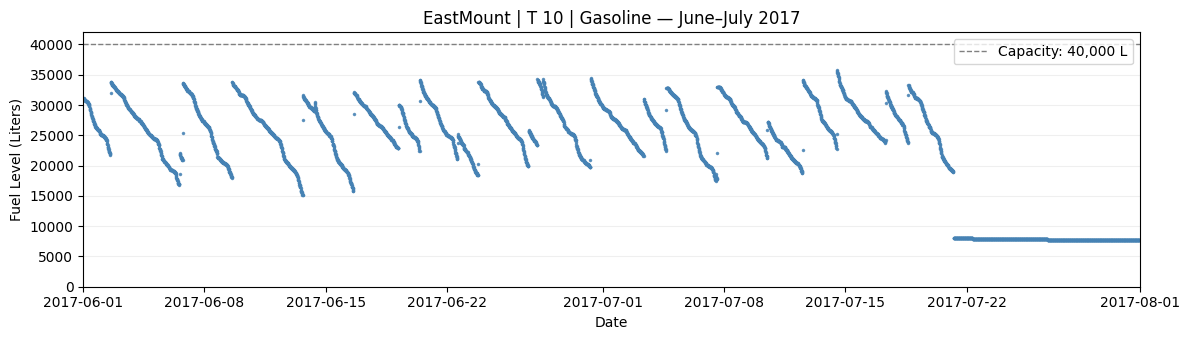

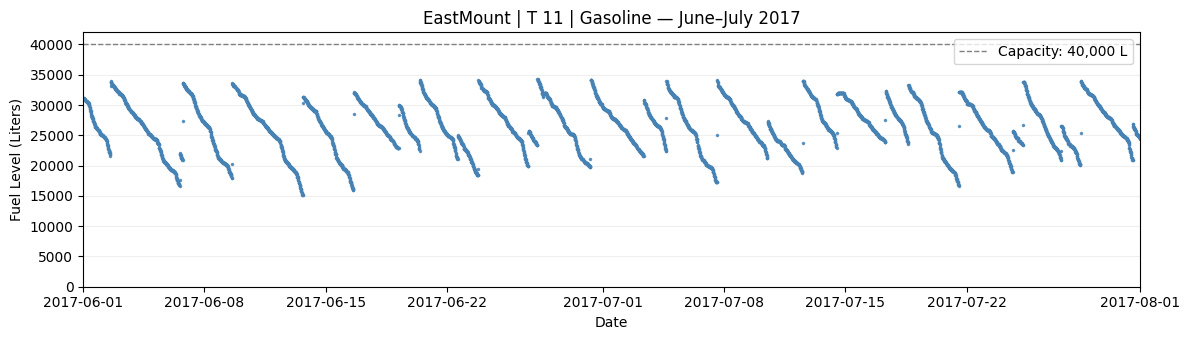

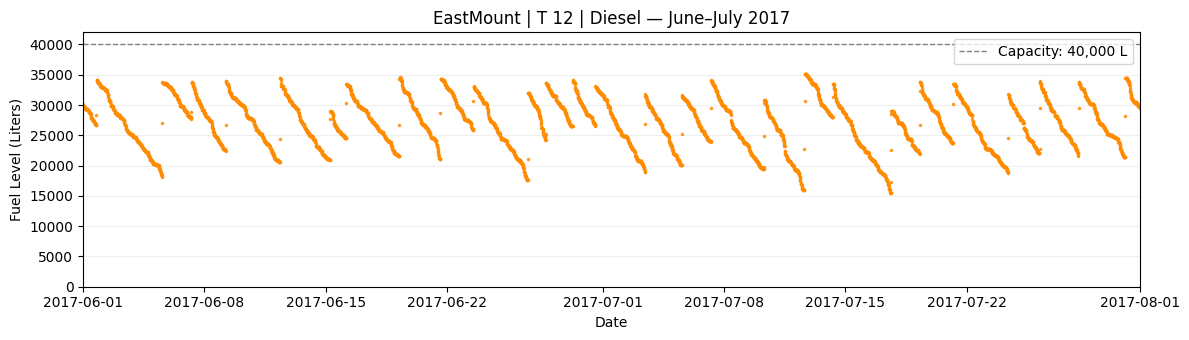

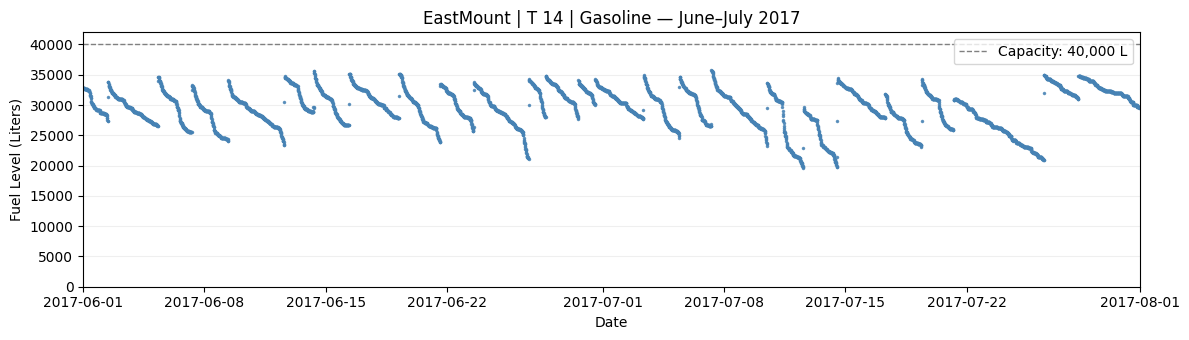

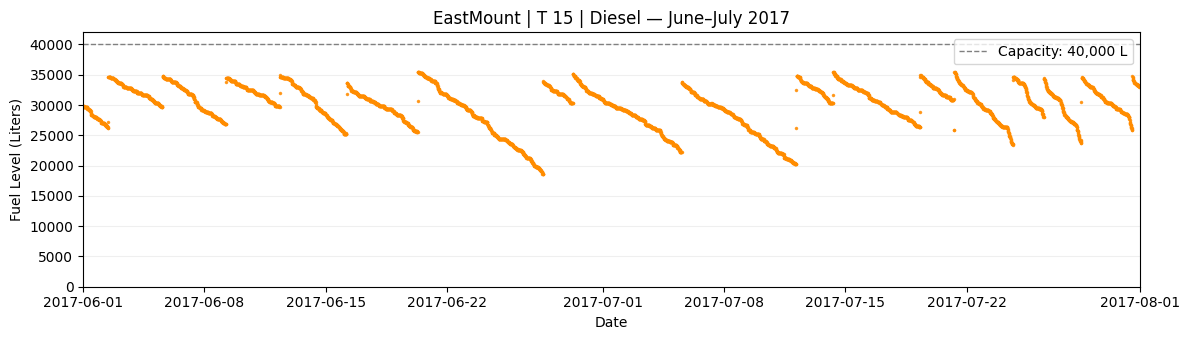

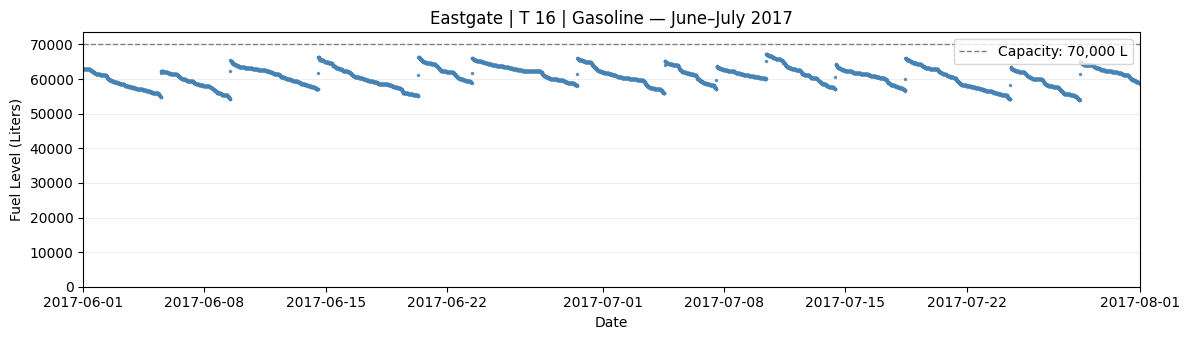

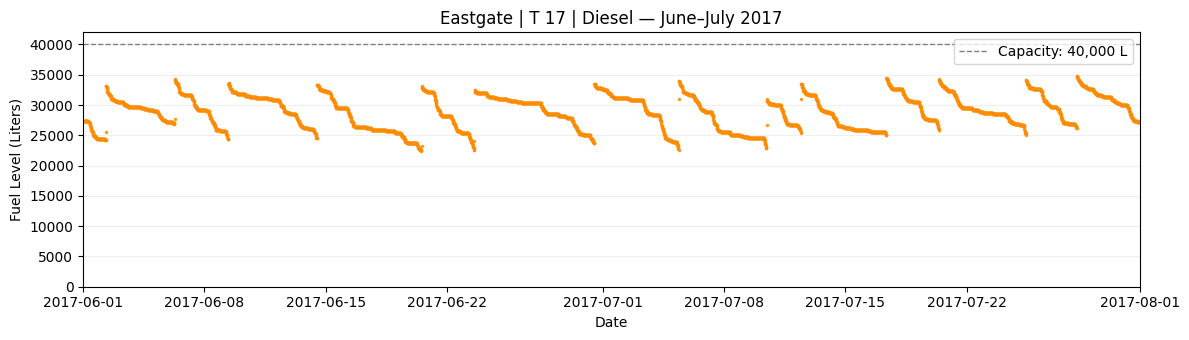

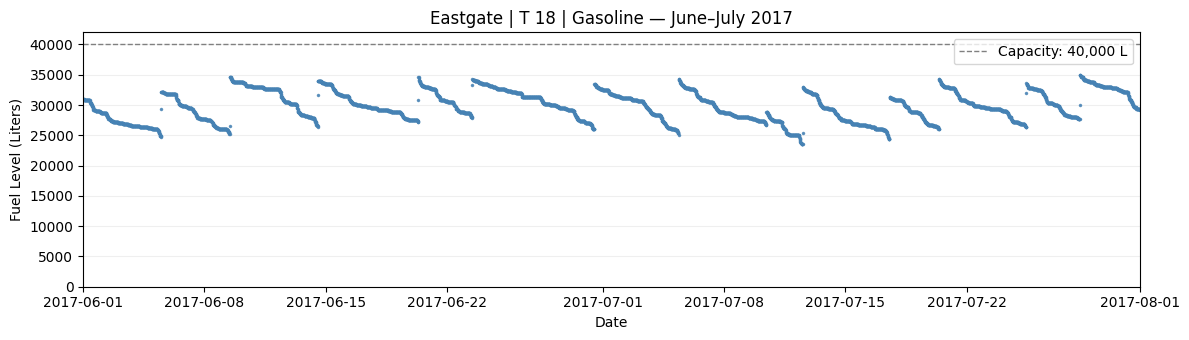

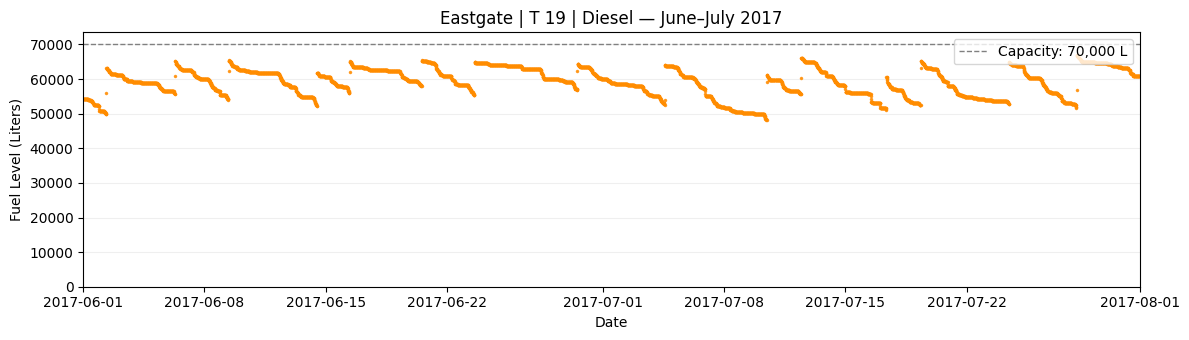

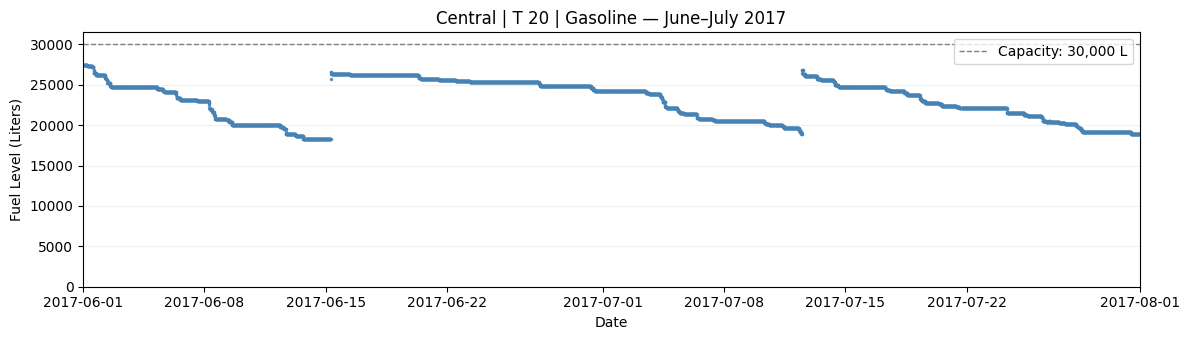

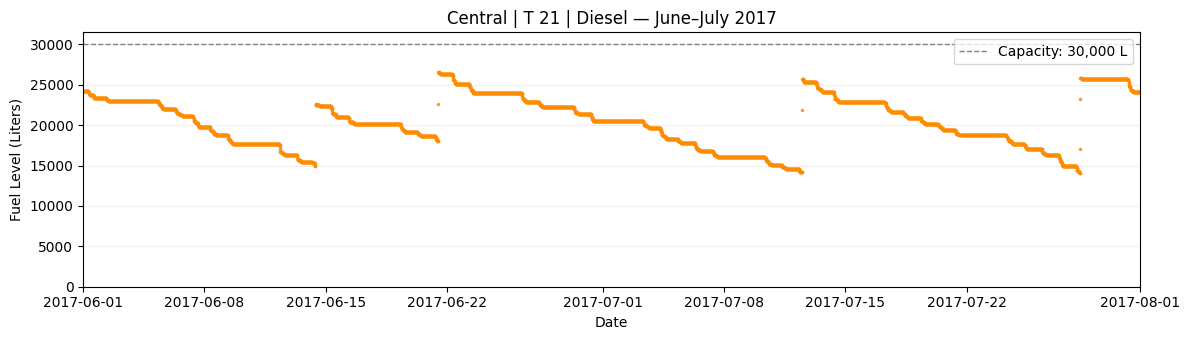

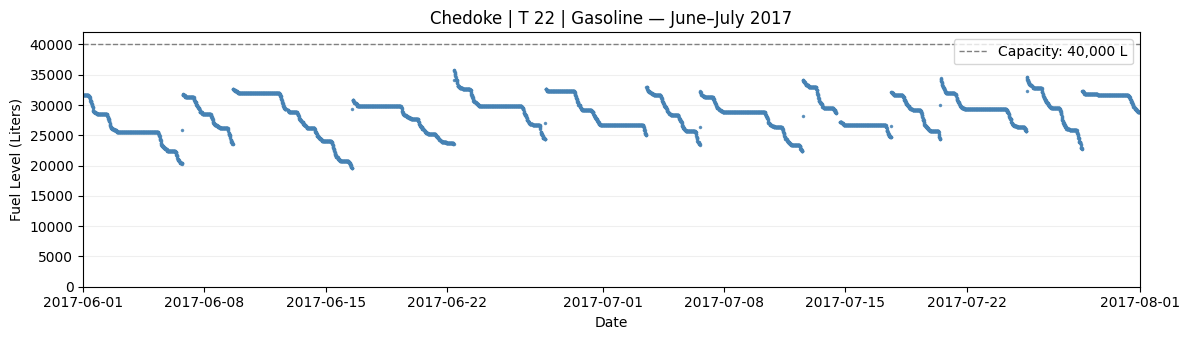

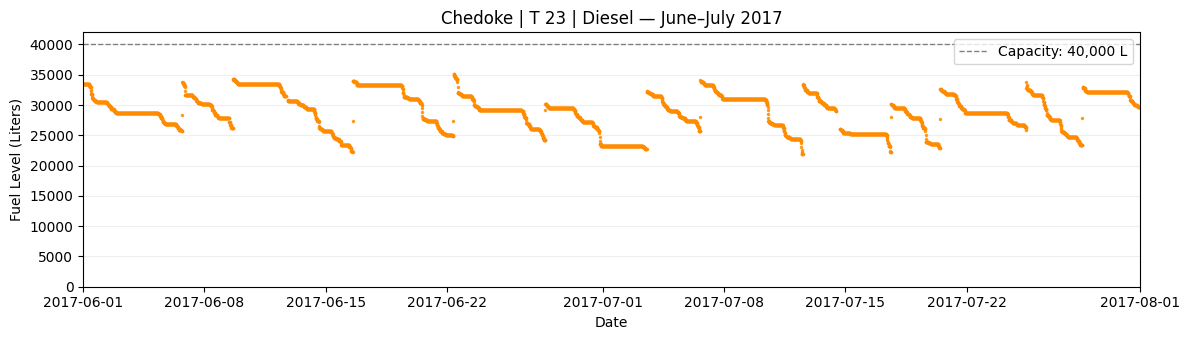

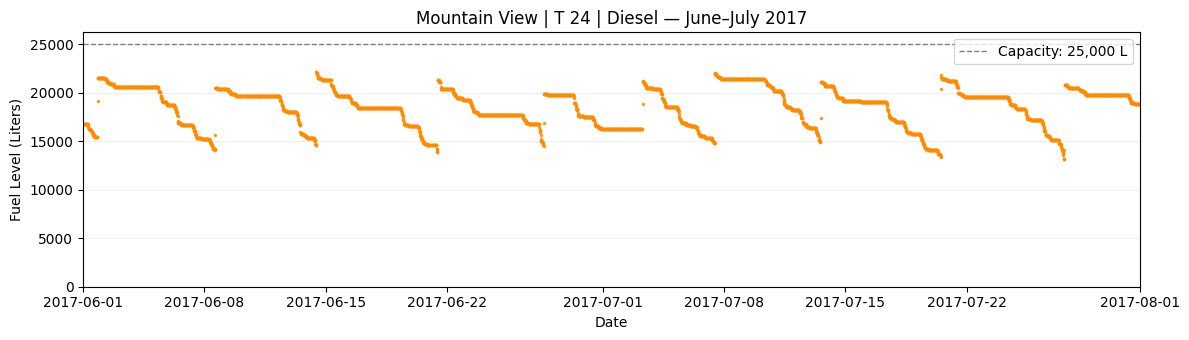

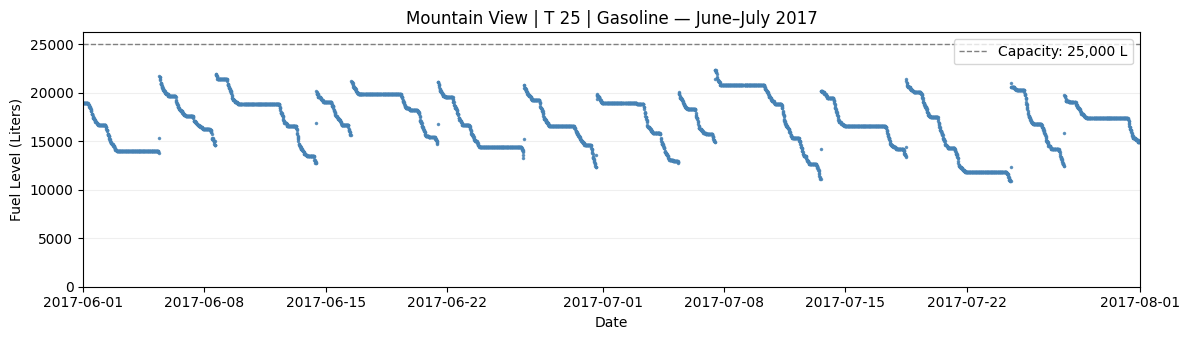

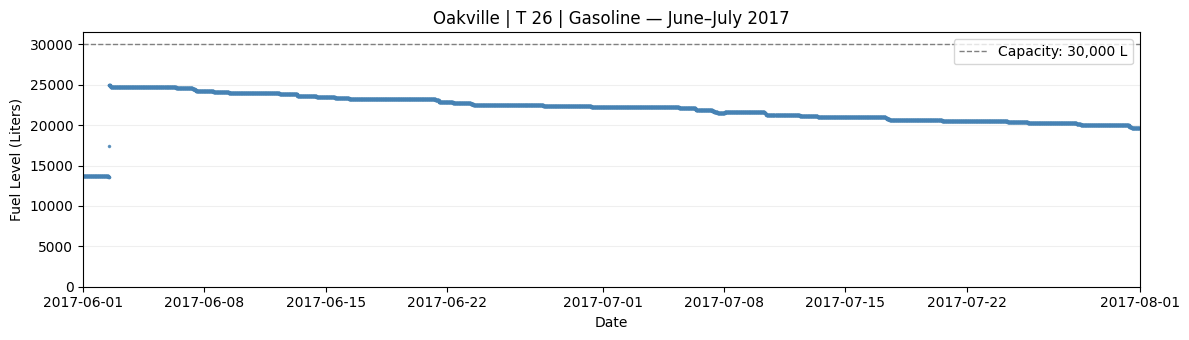

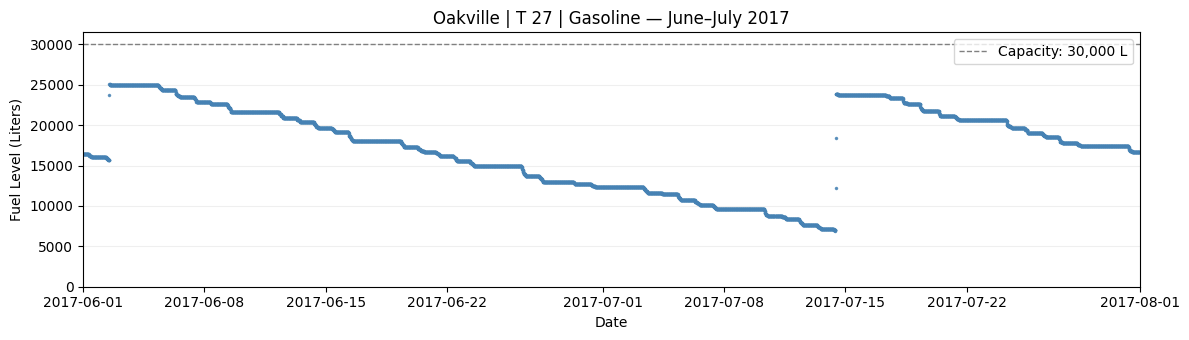

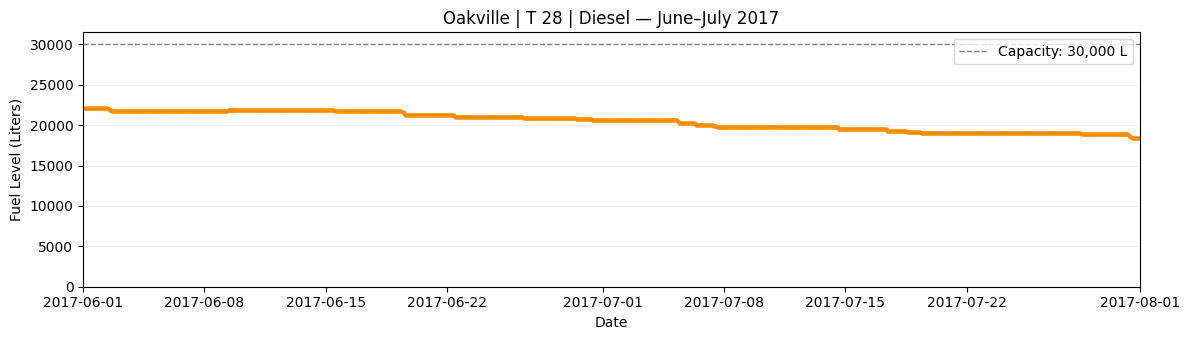

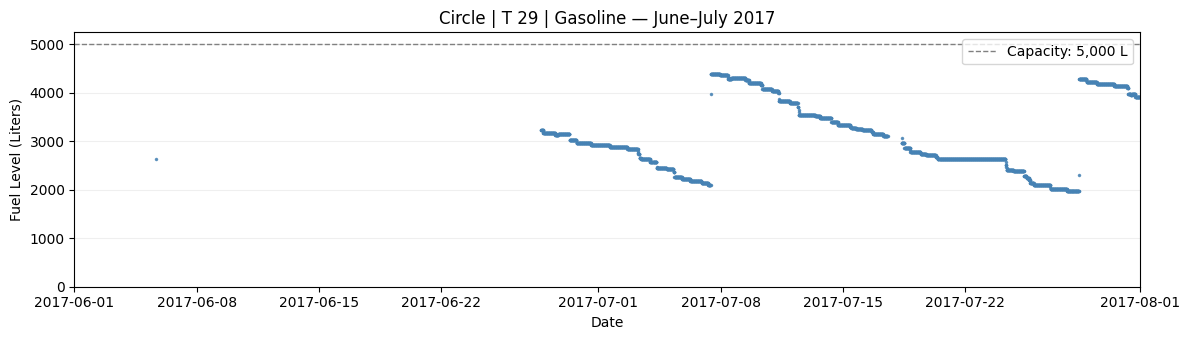

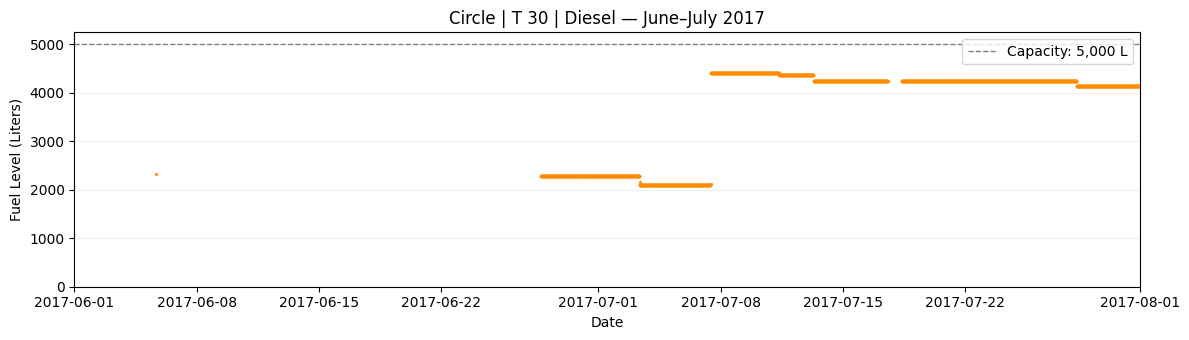

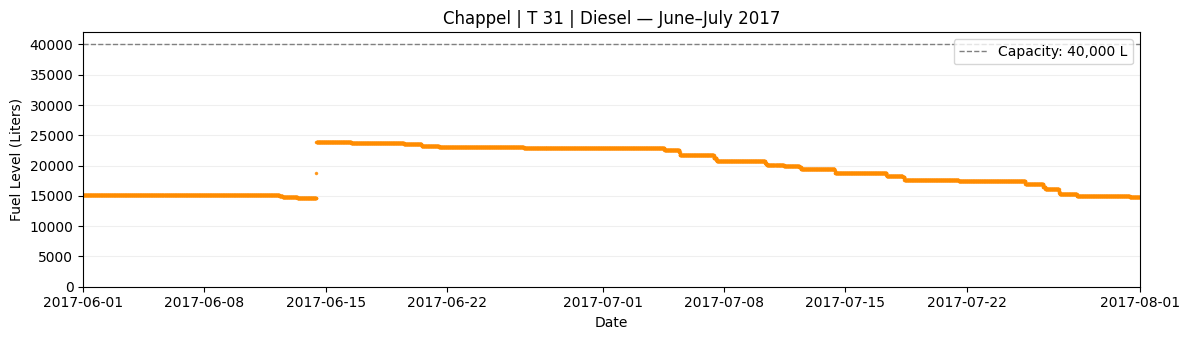

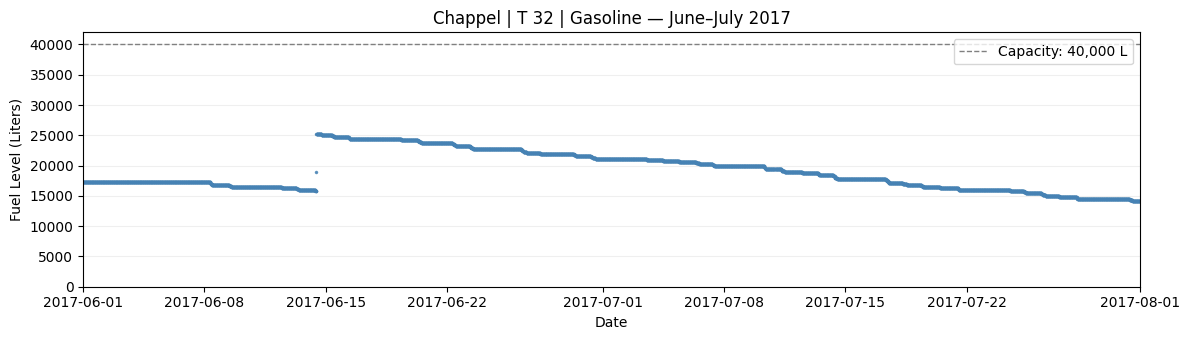

,Tank Location,Tank Type,Tank ID,Minimum_Inventory,Low_Reading_Share,Zero_Readings,Positive_Change_Signals
0,1,D,T 12,2567.0,0.000334,0,5686
1,1,D,T 15,6814.0,0.000000,0,3747
2,1,G,T 10,4483.0,0.000000,0,1509
3,1,G,T 11,7458.0,0.000000,0,5475
4,1,G,T 14,9048.0,0.000000,0,2435
5,2,D,T 17,11822.0,0.000000,0,2098
6,2,D,T 19,43590.0,0.000000,0,3225
7,2,G,T 16,47496.0,0.000000,0,2779
8,2,G,T 18,12091.0,0.000000,0,1734
9,3,D,T 21,8548.0,0.000000,0,1323


,Tank Location,Tank Type,Tank ID,First_Low_Reading,Last_Low_Reading
0,1,D,T 12,2019-07-01 03:00:00,2019-07-22 13:44:00


In [6]:
# pick two months for tank plots
fuel_plot = fuel_merged.loc[
    (fuel_merged["Timestamp"] >= "2017-06-01")
    & (fuel_merged["Timestamp"] < "2017-08-01")
].copy()

# plot fuel levels for each tank
for tank, tank_data in fuel_plot.groupby("Tank ID"):
    start = "2017-06-01"
    end = "2017-08-01"
    period = "June–July 2017"
    station = tank_data["Gas Station Name"].iloc[0]
    fuel_type = tank_data["Tank Type"].iloc[0]
    capacity = tank_data["Tank Capacity"].iloc[0]
    color = "steelblue"
    fuel_label = "Gasoline"
    if fuel_type == "D":
        color = "darkorange"
        fuel_label = "Diesel"

    fig, ax = plt.subplots(figsize=(12, 3.5))
    plt.plot(
        tank_data["Timestamp"], tank_data["Fuel_Level"],
        marker="o", linestyle="", markersize=1.5,
        color=color, alpha=0.8
    )
    plt.plot(
        [pd.to_datetime(start), pd.to_datetime(end)],
        [capacity, capacity], color="gray", linestyle="--", linewidth=1,
        label=f"Capacity: {capacity:,} L"
    )
    plt.axis([pd.to_datetime(start), pd.to_datetime(end), 0, capacity * 1.05])
    plt.title(f"{station} | {tank} | {fuel_label} — {period}", fontsize=12)
    plt.xlabel("Date")
    plt.ylabel("Fuel Level (Liters)")
    ax.grid(axis="y", alpha=0.2)
    plt.xticks(rotation=0)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

# check low readings and possible refills
fuel_merged["Low_Inventory"] = fuel_merged["Fuel_Level"] <= 0.10 * fuel_merged["Tank Capacity"]
fuel_merged["Zero_Inventory"] = fuel_merged["Fuel_Level"] == 0
fuel_merged["Replenishment_Signal"] = (
    (fuel_merged["Fuel_Change"] > 0)
    & (fuel_merged["Time_Change"] <= "0 days 01:00:00")
)
inventory_summary = fuel_merged.groupby(
    ["Tank Location", "Tank Type", "Tank ID"], as_index=False
).agg(
    Minimum_Inventory=("Fuel_Level", "min"),
    Low_Reading_Share=("Low_Inventory", "mean"),
    Zero_Readings=("Zero_Inventory", "sum"),
    Positive_Change_Signals=("Replenishment_Signal", "sum")
)
display(inventory_summary)

# show low inventory periods for follow-up
low_inventory_periods = fuel_merged.loc[fuel_merged["Low_Inventory"]].groupby(
    ["Tank Location", "Tank Type", "Tank ID"], as_index=False
).agg(First_Low_Reading=("Timestamp", "min"), Last_Low_Reading=("Timestamp", "max"))
display(low_inventory_periods)


### Station and fuel-type inventory assessment

Calculate hourly average readings for each tank. Combine tanks of the same fuel type only in hours when all relevant tanks report. Compare combined inventory with 10% of capacity and seven days of estimated demand.


In [7]:
# work out hourly mean inventory for each tank
fuel_hourly = fuel_merged.set_index("Timestamp").groupby(
    ["Tank Location", "Tank Type", "Tank ID"]
)["Fuel_Level"].resample("h").mean().dropna().reset_index()

# combine tank inventories within the same hour
station_inventory = fuel_hourly.groupby(
    ["Tank Location", "Tank Type", "Timestamp"], as_index=False
).agg(Fuel_Level=("Fuel_Level", "sum"), Reporting_Tanks=("Tank ID", "nunique"))
tank_counts = tanks.groupby(["Tank Location", "Tank Type"], as_index=False).agg(
    Expected_Tanks=("Tank ID", "nunique"), Total_Capacity=("Tank Capacity", "sum")
)
station_inventory = pd.merge(station_inventory, tank_counts, on=["Tank Location", "Tank Type"], how="left")
station_inventory = station_inventory.loc[
    station_inventory["Reporting_Tanks"] == station_inventory["Expected_Tanks"]
].copy()
station_inventory["Low_Inventory"] = station_inventory["Fuel_Level"] <= 0.10 * station_inventory["Total_Capacity"]
station_risk = station_inventory.groupby(["Tank Location", "Tank Type"], as_index=False).agg(
    Complete_Hours=("Timestamp", "count"),
    Minimum_Hourly_Inventory=("Fuel_Level", "min"),
    Low_Hour_Share=("Low_Inventory", "mean")
)
# compare inventory with seven days of estimated demand
station_inventory = pd.merge(station_inventory, daily_consumption, on=["Tank Location", "Tank Type"], how="left")
station_inventory["Below_Seven_Days"] = station_inventory["Fuel_Level"] < 7 * station_inventory["Average_Daily_Consumption"]
reserve_history = station_inventory.groupby(["Tank Location", "Tank Type"], as_index=False).agg(
    Below_Reserve_Hour_Share=("Below_Seven_Days", "mean")
)
station_risk = pd.merge(station_risk, reserve_history, on=["Tank Location", "Tank Type"], how="left")
display(station_risk)


,Tank Location,Tank Type,Complete_Hours,Minimum_Hourly_Inventory,Low_Hour_Share,Below_Reserve_Hour_Share
0,1,D,20958,33017.50,0.0,0.285333
1,1,G,20912,37107.00,0.0,0.696968
2,2,D,21842,64003.25,0.0,0.000000
3,2,G,21841,65280.50,0.0,0.000000
4,3,D,17065,8548.00,0.0,0.000000
5,3,G,17067,8721.50,0.0,0.000000
6,4,D,20967,14257.00,0.0,0.003148
7,4,G,20968,16939.50,0.0,0.000000
8,5,D,21778,8075.00,0.0,0.000000
9,5,G,21777,4826.00,0.0,0.116453


### Current delivery performance

Summarize delivery quantities, ordering frequency, weighted cost per liter, and quantity discounts by station and fuel type. Calculate discount savings and estimate the price before discounts.


In [8]:
# work out purchase cost per liter
invoice_merged["Cost_Per_Liter"] = (invoice_merged["Gross Purchase Cost"] / invoice_merged["Amount Purchased"])

# assign the discount per liter
invoice_merged["Discount_Per_Liter"] = 0.00

invoice_merged.loc[invoice_merged["Amount Purchased"] >= 15000, "Discount_Per_Liter"] = 0.02

invoice_merged.loc[invoice_merged["Amount Purchased"] >= 25000, "Discount_Per_Liter"] = 0.03

invoice_merged.loc[invoice_merged["Amount Purchased"] >= 40000, "Discount_Per_Liter"] = 0.04

# work out current discount savings
invoice_merged["Discount_Savings"] = (invoice_merged["Amount Purchased"] * invoice_merged["Discount_Per_Liter"])

invoice_merged.head()

# sum up current purchasing performance
current_summary = invoice_merged.groupby(["Invoice Gas Station Location", "Fuel Type"], as_index=False).agg(Invoice_Count=("Invoice ID", "count"), Total_Purchased=("Amount Purchased", "sum"), Average_Order=("Amount Purchased", "mean"), Total_Cost=("Gross Purchase Cost", "sum"), Current_Discount_Savings=("Discount_Savings", "sum"))

# work out volume-weighted cost per liter
current_summary["Cost_Per_Liter"] = (current_summary["Total_Cost"] / current_summary["Total_Purchased"])

display(current_summary)

# find distinct ordering dates
order_dates = invoice_merged[[
    "Invoice Gas Station Location", "Fuel Type", "Invoice Date"
]].drop_duplicates()

order_dates = order_dates.sort_values([
    "Invoice Gas Station Location", "Fuel Type", "Invoice Date"
])

# work out time between ordering dates
order_dates["Time_Between_Orders"] = order_dates.groupby(
    ["Invoice Gas Station Location", "Fuel Type"]
)["Invoice Date"].diff()

# sum up ordering frequency
order_frequency = order_dates.groupby(
    ["Invoice Gas Station Location", "Fuel Type"]
).agg(
    Ordering_Days=("Invoice Date", "count"),
    Average_Order_Interval=("Time_Between_Orders", "mean"),
    Longest_Order_Interval=("Time_Between_Orders", "max")
)

display(order_frequency)

# count invoices by station, fuel type, and discount rate
discount_counts = invoice_merged.pivot_table(
    index=["Invoice Gas Station Location", "Fuel Type"],
    columns="Discount_Per_Liter",
    aggfunc="size",
    fill_value=0
)

display(discount_counts)

# estimate price per liter before the quantity discount
invoice_merged["Price_Before_Discount"] = (
    invoice_merged["Cost_Per_Liter"]
    + invoice_merged["Discount_Per_Liter"]
)

invoice_merged[[
    "Amount Purchased", "Cost_Per_Liter",
    "Discount_Per_Liter", "Price_Before_Discount"
]].head()

,Invoice Gas Station Location,Fuel Type,Invoice_Count,Total_Purchased,Average_Order,Total_Cost,Current_Discount_Savings,Cost_Per_Liter
0,1,D,599,4.872458e+06,8134.320588,5.896560e+06,2347.70624,1.210182
1,1,G,762,1.086621e+07,14260.119706,1.230239e+07,188239.66928,1.132170
2,2,D,347,3.460900e+06,9973.774663,4.015548e+06,6761.38656,1.160261
3,2,G,285,2.822514e+06,9903.557109,3.040002e+06,3534.93504,1.077055
4,3,D,41,4.318151e+05,10532.076098,4.929777e+05,319.43968,1.141641
5,3,G,39,4.235187e+05,10859.452718,4.473295e+05,1635.61088,1.056221
6,4,D,184,1.632468e+06,8872.111043,1.967561e+06,343.36672,1.205268
7,4,G,172,1.578618e+06,9178.010326,1.730773e+06,0.00000,1.096385
8,5,D,125,8.117340e+05,6493.871616,9.946808e+05,0.00000,1.225378
9,5,G,155,1.346713e+06,8688.469781,1.487689e+06,0.00000,1.104682


Ordering_Days  \
Invoice Gas Station Location Fuel Type                  
1                            D                    450   
                             G                    536   
2                            D                    226   
                             G                    164   
3                            D                     41   
                             G                     39   
4                            D                    183   
                             G                    172   
5                            D                    125   
                             G                    154   
6                            D                      7   
                             G                     30   
7                            D                      8   
                             G                     44   
8                            D                      9   
                             G                     19   

                                           Average_Order_Interval  \
Invoice Gas Station Location Fuel Type                              
1                            D          2 days 03:02:48.374164810   
                             G          1 days 18:47:46.542056074   
2                            D                    4 days 05:45:36   
                             G          5 days 19:26:08.098159509   
3                            D                   19 days 14:24:00   
                             G         23 days 09:28:25.263157894   
4                            D          5 days 05:48:07.912087912   
                             G          5 days 13:28:25.263157894   
5                            D          7 days 15:40:38.709677419   
                             G          6 days 04:42:21.176470588   
6                            D                  140 days 20:00:00   
                             G         31 days 14:53:47.586206896   
7                            D         94 days 13:42:51.428571429   
                             G         21 days 08:55:48.837209302   
8                            D                   97 days 00:00:00   
                             G                   49 days 06:40:00   

                                       Longest_Order_Interval  
Invoice Gas Station Location Fuel Type                         
1                            D                         6 days  
                             G                         5 days  
2                            D                        91 days  
                             G                        92 days  
3                            D                        37 days  
                             G                        94 days  
4                            D                        11 days  
                             G                        14 days  
5                            D                        14 days  
                             G                        12 days  
6                            D                       176 days  
                             G                        67 days  
7                            D                       140 days  
                             G                       127 days  
8                            D                       127 days  
                             G                       127 days

Discount_Per_Liter                      0.00  0.02  0.03
Invoice Gas Station Location Fuel Type                  
1                            D           592     7     0
                             G           498    87   177
2                            D           327    20     0
                             G           274    11     0
3                            D            40     1     0
                             G            34     5     0
4                            D           183     1     0
                             G           172     0     0
5                            D           125     0     0
                             G           155     0     0
6                            D             7     0     0
                             G            31     4     0
7                            D             8     0     0
                             G            44     0     0
8                            D             8     1     0
                             G            17     2     0

,Amount Purchased,Cost_Per_Liter,Discount_Per_Liter,Price_Before_Discount
0,6609.600,1.145428,0.0,1.145428
1,9338.736,1.337639,0.0,1.337639
2,13377.824,1.273327,0.0,1.273327
3,9432.112,1.337640,0.0,1.337640
4,9139.200,1.243413,0.0,1.243413


### Question I — Findings and conclusion

We combined the fuel-level files with `pd.concat()` and converted dates with `pd.to_datetime()`. We removed 42 incomplete invoices, two missing readings, and 71 exact duplicates, then averaged 44 conflicting tank/timestamp pairs. Following the instructor's clarification, we excluded premium and changed U to G. The remaining identifiers matched, quantities were positive, and readings were within capacity. We linked readings to tanks by Tank ID and tanks to stations by location. Grouping capacity by station and fuel type before linking invoices prevented double-counting quantities and costs.

The June–July plots show fuel dropping between refills. Station 1 orders most often—about every 1.8 days for gasoline and 2.1 days for diesel. Stations 2, 4, and 5 generally order every 4–8 days; lower-demand groups order less often. Station 1's T 12 reached 2,567 liters, with low readings occurring between July 1 and July 22, 2019, rather than throughout that period. No zero readings were recorded. Combined inventory was below seven days of estimated demand in 69.7% of observed complete hours for Station 1 gasoline, 28.5% for Station 1 diesel, 11.6% for Station 5 gasoline, and 0.3% for Station 4 diesel. Station 1 needs the most attention; other groups without observed shortfalls appear better buffered. These results show reduced reserve coverage, not confirmed stockouts. Gaps leave some periods unknown, and hourly averages can hide brief lows. Upward jumps suggest deliveries but do not confirm them.

We estimated consumption by dividing inventory decreases by elapsed days across nonincreasing intervals of one hour or less, then adding tank rates by station and fuel type. This accounts for uneven reporting and excludes long gaps that could hide deliveries. Consumption during refills, measurement fluctuations, the one-hour cutoff, and differences in reporting coverage limit accuracy.

The outputs give delivery quantities, frequency, weighted cost per liter, and discount savings for each station and fuel type. Average deliveries range from about 1,385 to 14,260 liters, with weighted prices of CAD 1.06–1.23/L. Savings equal delivery liters times the applicable discount. Of 2,831 invoices, 88.8% earned no discount; 139 earned CAD 0.02/L and 177 earned CAD 0.03/L. Only Station 1 gasoline reached CAD 0.03/L, and none reached CAD 0.04/L. Gross Purchase Cost already includes discounts, so we add the discount back to estimate the pre-discount price. Total savings were **CAD 205,979.41**. Overall, current ordering misses many discounts, while Station 1 also needs better reserve coverage.


## Question II — Recommend Improved Ordering Strategies

### Reserve, storage, and feasibility

Calculate the seven-day reserve and storage available at that level for each station and fuel type. Flag reserves that leave no room for replenishment.


In [9]:
# match station and fuel-type column names
daily_consumption = daily_consumption.rename(columns={
    "Tank Location": "Invoice Gas Station Location",
    "Tank Type": "Fuel Type"
})

# combine capacity and daily consumption
ordering_summary = pd.merge(
    capacity_summary,
    daily_consumption,
    on=["Invoice Gas Station Location", "Fuel Type"],
    how="left"
)

# work out the seven-day reserve
ordering_summary["Minimum_Reserve"] = (
    7 * ordering_summary["Average_Daily_Consumption"]
)

# work out available storage at the reserve level
ordering_summary["Available_Storage"] = (
    ordering_summary["Tank Capacity"] - ordering_summary["Minimum_Reserve"]
)

# check if there is room to order at the reserve
ordering_summary["Reserve_Feasible"] = (
    ordering_summary["Available_Storage"] > 0
)

ordering_summary

,Invoice Gas Station Location,Fuel Type,Tank Capacity,Average_Daily_Consumption,Minimum_Reserve,Available_Storage,Reserve_Feasible
0,1,D,80000,7679.342674,53755.398717,26244.601283,True
1,1,G,120000,11556.762121,80897.334844,39102.665156,True
2,2,D,110000,4250.487927,29753.415490,80246.584510,True
3,2,G,110000,3256.501967,22795.513771,87204.486229,True
4,3,D,30000,468.925843,3282.480903,26717.519097,True
5,3,G,30000,533.511858,3734.583005,26265.416995,True
6,4,D,40000,2148.114538,15036.801765,24963.198235,True
7,4,G,40000,1949.066738,13643.467164,26356.532836,True
8,5,D,25000,1086.666178,7606.663247,17393.336753,True
9,5,G,25000,1594.697751,11162.884259,13837.115741,True


### Compare feasible quantities and discount tiers

Compare orders of 10,000, 15,000, 25,000, and 40,000 liters, plus an order filling available storage. Identify which quantities fit at the reserve and estimate their intervals at average demand.


In [10]:
# create candidate order quantities and their discounts
order_options = pd.DataFrame({
    "Order_Quantity": [10000, 15000, 25000, 40000],
    "Proposed_Discount": [0.00, 0.02, 0.03, 0.04]
})

# match each station and fuel type with the order options
ordering_summary["Match"] = 1
order_options["Match"] = 1

order_scenarios = pd.merge(
    ordering_summary, order_options, on="Match", how="inner"
).drop(columns=["Match"])

ordering_summary = ordering_summary.drop(columns=["Match"])

# check whether each order fits at the reserve level
order_scenarios["Order_Feasible"] = (
    order_scenarios["Reserve_Feasible"]
    & (order_scenarios["Order_Quantity"] <= order_scenarios["Available_Storage"])
)

display(order_scenarios)

# add an option that fills the space available at the reserve
full_storage_options = ordering_summary.copy()
full_storage_options["Order_Quantity"] = full_storage_options["Available_Storage"]

# set the quantity discounts
full_storage_options["Proposed_Discount"] = 0.00

full_storage_options.loc[
    full_storage_options["Order_Quantity"] >= 15000, "Proposed_Discount"
] = 0.02

full_storage_options.loc[
    full_storage_options["Order_Quantity"] >= 25000, "Proposed_Discount"
] = 0.03

full_storage_options.loc[
    full_storage_options["Order_Quantity"] >= 40000, "Proposed_Discount"
] = 0.04

full_storage_options["Order_Feasible"] = full_storage_options["Reserve_Feasible"]

# add these options to the comparison
order_scenarios = pd.concat(
    [order_scenarios, full_storage_options], ignore_index=True
)

# estimate days between orders at average demand
order_scenarios["Days_Between_Orders"] = (
    order_scenarios["Order_Quantity"]
    / order_scenarios["Average_Daily_Consumption"]
)

order_scenarios.loc[order_scenarios["Order_Feasible"]]

,Invoice Gas Station Location,Fuel Type,Tank Capacity,Average_Daily_Consumption,Minimum_Reserve,Available_Storage,Reserve_Feasible,Order_Quantity,Proposed_Discount,Order_Feasible
0,1,D,80000,7679.342674,53755.398717,26244.601283,True,10000,0.00,True
1,1,D,80000,7679.342674,53755.398717,26244.601283,True,15000,0.02,True
2,1,D,80000,7679.342674,53755.398717,26244.601283,True,25000,0.03,True
3,1,D,80000,7679.342674,53755.398717,26244.601283,True,40000,0.04,False
4,1,G,120000,11556.762121,80897.334844,39102.665156,True,10000,0.00,True
...,...,...,...,...,...,...,...,...,...,...
59,8,D,40000,91.895620,643.269343,39356.730657,True,40000,0.04,False
60,8,G,40000,270.493376,1893.453629,38106.546371,True,10000,0.00,True
61,8,G,40000,270.493376,1893.453629,38106.546371,True,15000,0.02,True
62,8,G,40000,270.493376,1893.453629,38106.546371,True,25000,0.03,True


,Invoice Gas Station Location,Fuel Type,Tank Capacity,Average_Daily_Consumption,Minimum_Reserve,Available_Storage,Reserve_Feasible,Order_Quantity,Proposed_Discount,Order_Feasible,Days_Between_Orders
0,1,D,80000,7679.342674,53755.398717,26244.601283,True,10000.000000,0.00,True,1.302195
1,1,D,80000,7679.342674,53755.398717,26244.601283,True,15000.000000,0.02,True,1.953292
2,1,D,80000,7679.342674,53755.398717,26244.601283,True,25000.000000,0.03,True,3.255487
4,1,G,120000,11556.762121,80897.334844,39102.665156,True,10000.000000,0.00,True,0.865294
5,1,G,120000,11556.762121,80897.334844,39102.665156,True,15000.000000,0.02,True,1.297941
6,1,G,120000,11556.762121,80897.334844,39102.665156,True,25000.000000,0.03,True,2.163236
8,2,D,110000,4250.487927,29753.415490,80246.584510,True,10000.000000,0.00,True,2.352671
9,2,D,110000,4250.487927,29753.415490,80246.584510,True,15000.000000,0.02,True,3.529007
10,2,D,110000,4250.487927,29753.415490,80246.584510,True,25000.000000,0.03,True,5.881678
11,2,D,110000,4250.487927,29753.415490,80246.584510,True,40000.000000,0.04,True,9.410684


### Compare equal-volume savings

Use the historical delivered volume for every scenario. Calculate full orders and a final smaller delivery, apply each delivery's discount, and compare savings with current discounts.


In [11]:
# add current purchase volume and savings to each scenario
order_scenarios = pd.merge(
    order_scenarios,
    current_summary[[
        "Invoice Gas Station Location", "Fuel Type",
        "Total_Purchased", "Current_Discount_Savings"
    ]],
    on=["Invoice Gas Station Location", "Fuel Type"],
    how="left"
)

# estimate savings if every liter gets this discount
order_scenarios["Potential_Discount_Savings"] = (
    order_scenarios["Total_Purchased"]
    * order_scenarios["Proposed_Discount"]
)

order_scenarios["Potential_Incremental_Savings"] = (
    order_scenarios["Potential_Discount_Savings"]
    - order_scenarios["Current_Discount_Savings"]
)

order_scenarios.loc[order_scenarios["Order_Feasible"], [
    "Invoice Gas Station Location", "Fuel Type", "Order_Quantity",
    "Proposed_Discount", "Days_Between_Orders",
    "Current_Discount_Savings", "Potential_Discount_Savings",
    "Potential_Incremental_Savings"
]]

# keep feasible ordering scenarios
feasible_scenarios = order_scenarios.loc[
    order_scenarios["Order_Feasible"]
].copy()

# work out the number of full orders
feasible_scenarios["Full_Orders"] = (
    feasible_scenarios["Total_Purchased"]
    / feasible_scenarios["Order_Quantity"]
).astype(int)

# work out the remaining delivery quantity
feasible_scenarios["Remaining_Quantity"] = (
    feasible_scenarios["Total_Purchased"]
    - feasible_scenarios["Full_Orders"]
    * feasible_scenarios["Order_Quantity"]
)

feasible_scenarios[[
    "Invoice Gas Station Location", "Fuel Type",
    "Total_Purchased", "Order_Quantity",
    "Full_Orders", "Remaining_Quantity"
]]

# set the discount for the last smaller delivery
feasible_scenarios["Remaining_Discount"] = 0.00

feasible_scenarios.loc[
    feasible_scenarios["Remaining_Quantity"] >= 15000, "Remaining_Discount"
] = 0.02

feasible_scenarios.loc[
    feasible_scenarios["Remaining_Quantity"] >= 25000, "Remaining_Discount"
] = 0.03

feasible_scenarios.loc[
    feasible_scenarios["Remaining_Quantity"] >= 40000, "Remaining_Discount"
] = 0.04

# work out savings from full orders and the remaining delivery
feasible_scenarios["Modeled_Discount_Savings"] = (
    feasible_scenarios["Full_Orders"]
    * feasible_scenarios["Order_Quantity"]
    * feasible_scenarios["Proposed_Discount"]
    + feasible_scenarios["Remaining_Quantity"]
    * feasible_scenarios["Remaining_Discount"]
)

feasible_scenarios["Modeled_Incremental_Savings"] = (
    feasible_scenarios["Modeled_Discount_Savings"]
    - feasible_scenarios["Current_Discount_Savings"]
)

feasible_scenarios[[
    "Invoice Gas Station Location", "Fuel Type", "Order_Quantity",
    "Current_Discount_Savings", "Potential_Discount_Savings",
    "Modeled_Discount_Savings", "Modeled_Incremental_Savings"
]]

,Invoice Gas Station Location,Fuel Type,Order_Quantity,Current_Discount_Savings,Potential_Discount_Savings,Modeled_Discount_Savings,Modeled_Incremental_Savings
0,1,D,10000.000000,2347.70624,0.00000,0.000000,-2347.706240
1,1,D,15000.000000,2347.70624,97449.16064,97200.000000,94852.293760
2,1,D,25000.000000,2347.70624,146173.74096,145949.160640,143601.454400
4,1,G,10000.000000,188239.66928,0.00000,0.000000,-188239.669280
5,1,G,15000.000000,188239.66928,217324.22432,217200.000000,28960.330720
6,1,G,25000.000000,188239.66928,325986.33648,325824.224320,137584.555040
8,2,D,10000.000000,6761.38656,0.00000,0.000000,-6761.386560
9,2,D,15000.000000,6761.38656,69217.99616,69000.000000,62238.613440
10,2,D,25000.000000,6761.38656,103826.99424,103500.000000,96738.613440
11,2,D,40000.000000,6761.38656,138435.99232,138017.996160,131256.609600


### Recommended routine orders

Pick the smallest tested order that gets the best discount available. Where no discount is feasible, retain the historical average order capped by available storage. Recalculate savings for the selected quantities.


In [12]:
# pick the smallest order that gets the best feasible discount
proposed_policy = feasible_scenarios.sort_values(
    ["Proposed_Discount", "Order_Quantity"], ascending=[False, True]
).groupby(["Invoice Gas Station Location", "Fuel Type"]).head(1).copy()

# add historical ordering performance
proposed_policy = pd.merge(proposed_policy, current_summary[[
    "Invoice Gas Station Location", "Fuel Type", "Average_Order", "Invoice_Count", "Cost_Per_Liter"
]], on=["Invoice Gas Station Location", "Fuel Type"], how="left")

# keep smaller historical orders when no discount is possible
proposed_policy.loc[proposed_policy["Proposed_Discount"] == 0, "Order_Quantity"] = proposed_policy["Average_Order"]
proposed_policy.loc[
    proposed_policy["Order_Quantity"] > proposed_policy["Available_Storage"], "Order_Quantity"
] = proposed_policy["Available_Storage"]

# update savings using the same total liters
proposed_policy["Full_Orders"] = (proposed_policy["Total_Purchased"] / proposed_policy["Order_Quantity"]).astype(int)
proposed_policy["Remaining_Quantity"] = proposed_policy["Total_Purchased"] - proposed_policy["Full_Orders"] * proposed_policy["Order_Quantity"]
proposed_policy["Remaining_Discount"] = 0.00
proposed_policy.loc[proposed_policy["Remaining_Quantity"] >= 15000, "Remaining_Discount"] = 0.02
proposed_policy.loc[proposed_policy["Remaining_Quantity"] >= 25000, "Remaining_Discount"] = 0.03
proposed_policy.loc[proposed_policy["Remaining_Quantity"] >= 40000, "Remaining_Discount"] = 0.04
proposed_policy["Modeled_Discount_Savings"] = (
    proposed_policy["Full_Orders"] * proposed_policy["Order_Quantity"] * proposed_policy["Proposed_Discount"]
    + proposed_policy["Remaining_Quantity"] * proposed_policy["Remaining_Discount"]
)
proposed_policy["Modeled_Incremental_Savings"] = proposed_policy["Modeled_Discount_Savings"] - proposed_policy["Current_Discount_Savings"]
proposed_policy["Replenishment_Trigger"] = proposed_policy["Minimum_Reserve"]
proposed_policy["Days_Between_Orders"] = proposed_policy["Order_Quantity"] / proposed_policy["Average_Daily_Consumption"]
proposed_policy = proposed_policy.sort_values(["Invoice Gas Station Location", "Fuel Type"])


In [13]:
# work out inventory immediately after replenishment
proposed_policy["Inventory_After_Order"] = (
    proposed_policy["Replenishment_Trigger"]
    + proposed_policy["Order_Quantity"]
)

# work out unused capacity after delivery
proposed_policy["Storage_Remaining"] = (
    proposed_policy["Available_Storage"]
    - proposed_policy["Order_Quantity"]
)

proposed_policy[[
    "Invoice Gas Station Location", "Fuel Type",
    "Tank Capacity", "Replenishment_Trigger",
    "Order_Quantity", "Inventory_After_Order", "Storage_Remaining"
]]

# work out the theoretical maximum discount savings
proposed_policy["Theoretical_Max_Savings"] = (
    proposed_policy["Total_Purchased"] * 0.04
)

# compare current, modeled, and theoretical savings
proposed_policy[[
    "Invoice Gas Station Location", "Fuel Type",
    "Current_Discount_Savings", "Modeled_Discount_Savings",
    "Modeled_Incremental_Savings", "Theoretical_Max_Savings"
]]

# add up savings across all stations
print("Current discount savings (CAD):",
      proposed_policy["Current_Discount_Savings"].sum())

print("Modeled discount savings (CAD):",
      proposed_policy["Modeled_Discount_Savings"].sum())

print("Modeled incremental savings (CAD):",
      proposed_policy["Modeled_Incremental_Savings"].sum())

print("Theoretical maximum discount savings (CAD):",
      proposed_policy["Theoretical_Max_Savings"].sum())

Current discount savings (CAD): 205979.40592
Modeled discount savings (CAD): 868262.4326399999
Modeled incremental savings (CAD): 662283.0267199998
Theoretical maximum discount savings (CAD): 1163067.9225600003


### Final comparison by station and fuel type

Compare current ordering with the proposed policy over the same observed purchase volume. Capacity, consumption, triggers, and order quantities are in liters (consumption is liters/day); prices and discounts are CAD/L; savings are CAD. Order intervals are days or timedeltas. The proposed savings describe a quantity-discount scenario, not a replay of the historical inventory.


In [14]:
# show current deliveries and the proposed policy together
proposed_policy = pd.merge(proposed_policy, order_frequency.reset_index(), on=["Invoice Gas Station Location", "Fuel Type"], how="left")
display(proposed_policy[[
    "Invoice Gas Station Location", "Fuel Type", "Tank Capacity", "Average_Daily_Consumption",
    "Invoice_Count", "Average_Order", "Average_Order_Interval", "Cost_Per_Liter",
    "Replenishment_Trigger", "Order_Quantity", "Proposed_Discount", "Days_Between_Orders",
    "Current_Discount_Savings", "Modeled_Discount_Savings", "Modeled_Incremental_Savings"
]].round(2))

# check that the recommended orders fit at the reserve
print("Orders exceeding storage:", (proposed_policy["Order_Quantity"] > proposed_policy["Available_Storage"]).sum())
print("Infeasible reserves:", (~proposed_policy["Reserve_Feasible"]).sum())


,Invoice Gas Station Location,Fuel Type,Tank Capacity,Average_Daily_Consumption,Invoice_Count,Average_Order,Average_Order_Interval,Cost_Per_Liter,Replenishment_Trigger,Order_Quantity,Proposed_Discount,Days_Between_Orders,Current_Discount_Savings,Modeled_Discount_Savings,Modeled_Incremental_Savings
0,1,D,80000,7679.34,599,8134.32,2 days 03:02:48.374164810,1.21,53755.40,25000.00,0.03,3.26,2347.71,145949.16,143601.45
1,1,G,120000,11556.76,762,14260.12,1 days 18:47:46.542056074,1.13,80897.33,25000.00,0.03,2.16,188239.67,325824.22,137584.56
2,2,D,110000,4250.49,347,9973.77,4 days 05:45:36,1.16,29753.42,40000.00,0.04,9.41,6761.39,138018.00,131256.61
3,2,G,110000,3256.50,285,9903.56,5 days 19:26:08.098159509,1.08,22795.51,40000.00,0.04,12.28,3534.94,112450.28,108915.34
4,3,D,30000,468.93,41,10532.08,19 days 14:24:00,1.14,3282.48,25000.00,0.03,53.31,319.44,12750.00,12430.56
5,3,G,30000,533.51,39,10859.45,23 days 09:28:25.263157894,1.06,3734.58,25000.00,0.03,46.86,1635.61,12470.37,10834.76
6,4,D,40000,2148.11,184,8872.11,5 days 05:48:07.912087912,1.21,15036.80,15000.00,0.02,6.98,343.37,32400.00,32056.63
7,4,G,40000,1949.07,172,9178.01,5 days 13:28:25.263157894,1.10,13643.47,25000.00,0.03,12.83,0.00,47250.00,47250.00
8,5,D,25000,1086.67,125,6493.87,7 days 15:40:38.709677419,1.23,7606.66,15000.00,0.02,13.80,0.00,16200.00,16200.00
9,5,G,25000,1594.70,155,8688.47,6 days 04:42:21.176470588,1.10,11162.88,8688.47,0.00,5.45,0.00,0.00,0.00


Orders exceeding storage: 0
Infeasible reserves: 0


### Question II — Findings and recommendations

We set each station/fuel group's reserve at seven times estimated daily consumption and calculated available storage as capacity minus reserve. All 16 groups have room to replenish, so none is infeasible. The outputs show each group's capacity, consumption, reserve, and available storage. Storage at the reserve—not total capacity alone—limits the discount. For example, Station 1 gasoline has 120,000 liters of capacity but only about 39,103 liters available at its reserve, so a 40,000-liter order would not fit.

We recommend **40,000 liters** for Station 2 gasoline and diesel and Station 6 gasoline, earning CAD 0.04/L. Order **25,000 liters** for Station 1 gasoline and diesel, Station 3 gasoline and diesel, Station 4 gasoline, Station 6 diesel, and Station 8 gasoline and diesel, earning CAD 0.03/L. Order **15,000 liters** for Station 4 diesel and Station 5 diesel, earning CAD 0.02/L. Station 5 gasoline and both Station 7 fuels cannot reach a discount while keeping the reserve, so retain their historical average quantities shown in the final output, capped by available storage. These choices use the smallest tested order at the best feasible discount, limiting extra cash tied up in fuel.

Using the same historical liters, modeled discounts rise from **CAD 205,979.41 to CAD 868,262.43**, giving **CAD 662,283.03 in additional savings over the observed period**. Each full order and final smaller delivery receives its own discount. The theoretical maximum of **CAD 1,163,067.92** assumes every liter earns CAD 0.04 regardless of storage constraints. Pre-discount prices are held fixed to isolate quantity savings.

Order when inventory reaches the seven-day reserve listed for each group. Using the assignment’s usable-capacity and immediate-delivery assumptions, continuous monitoring lets the recommended orders fit and preserve that reserve. Delivery costs are ignored. Seven days of average demand does not guarantee protection against demand spikes. Higher demand means ordering sooner; the estimated intervals are not a fixed schedule. Less frequent monitoring requires an earlier trigger and another storage check. Savings assume the reserve is already in place and do not recreate historical inventory balances. Demand estimates, missing records, and unmodeled holding and financing costs limit these savings estimates; future prices and supplier discounts may also change. Prioritize Station 1's reserve coverage and consolidate deliveries where discounts are feasible.


## Question III — Weekday Purchasing

In [15]:
#Calculate invoice cost per liter as Gross Purchase Cost divided by Amount Purchased
invoice_merged["cost per liter"] = invoice_merged["Gross Purchase Cost"]/invoice_merged["Amount Purchased"]
display(invoice_merged)#check

#Compare its distribution across days of the week, reporting the number of observations for each day.
invoice_merged["days of the week"] = invoice_merged["Invoice Date"].dt.day_name()
display(invoice_merged["days of the week"].value_counts())
cost_per_day_D = invoice_merged[invoice_merged["Fuel Type"]=="D"].groupby("days of the week")["cost per liter"].mean().sort_values()
cost_per_day_G = invoice_merged[invoice_merged["Fuel Type"]=="G"].groupby("days of the week")["cost per liter"].mean().sort_values()


print("average diesel cost (CAD/L)")
display(cost_per_day_D)
print("average gasoline cost (CAD/L)")
display(cost_per_day_G)

,Invoice Date,Invoice ID,Invoice Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Tank Capacity,Gas Station Location,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude,Cost_Per_Liter,Discount_Per_Liter,Discount_Savings,Price_Before_Discount,cost per liter
0,2017-01-02,10000.0,1,7570.82000,6609.600,G,120000,1,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.145428,0.0,0.0,1.145428,1.145428
1,2017-01-02,10001.0,1,12491.85300,9338.736,D,80000,1,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.337639,0.0,0.0,1.337639,1.337639
2,2017-01-02,10002.0,2,17034.34500,13377.824,D,110000,2,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.273327,0.0,0.0,1.273327,1.273327
3,2017-01-02,10003.0,2,12616.77153,9432.112,D,110000,2,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.337640,0.0,0.0,1.337640,1.337640
4,2017-01-02,10004.0,4,11363.80082,9139.200,D,40000,4,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.243413,0.0,0.0,1.243413,1.243413
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2826,2019-08-14,12826.0,2,14418.62669,8182.960,D,110000,2,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.762031,0.0,0.0,1.762031,1.762031
2827,2019-08-14,12827.0,2,7570.82000,4296.640,D,110000,2,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.762033,0.0,0.0,1.762033,1.762033
2828,2019-08-14,12828.0,4,8706.44300,6352.416,G,40000,4,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.370572,0.0,0.0,1.370572,1.370572
2829,2019-08-14,12829.0,4,13252.72041,7521.264,D,40000,4,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.762034,0.0,0.0,1.762034,1.762034


,count
days of the week,
Friday,803
Wednesday,606
Tuesday,549
Monday,522
Thursday,338
Saturday,13


average diesel cost (CAD/L)


,cost per liter
days of the week,
Saturday,1.095338
Thursday,1.249957
Monday,1.251885
Wednesday,1.253820
Friday,1.285570
Tuesday,1.327193


average gasoline cost (CAD/L)


,cost per liter
days of the week,
Saturday,1.034955
Monday,1.121444
Thursday,1.130905
Wednesday,1.132926
Friday,1.162882
Tuesday,1.209641


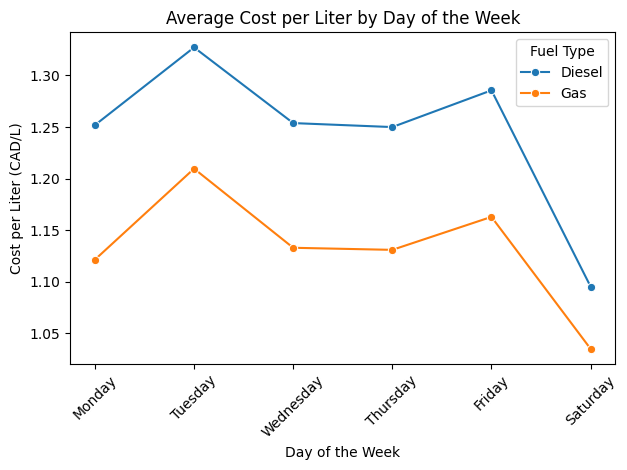

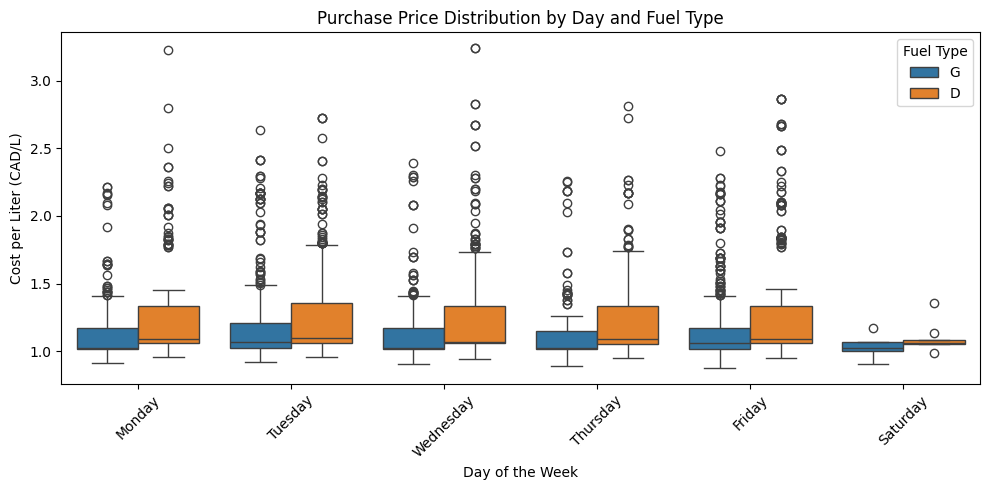

Fuel Type,D,G
days of the week,,
Friday,358,445
Monday,254,268
Saturday,8,5
Thursday,168,170
Tuesday,218,331
Wednesday,314,292


In [16]:
#Check whether weekday differences reflect fuel type, station, order size, quantity discounts, or broader price changes over time.
#check fuel type relationship with weekday
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# combine the two series
plot_data = pd.concat([
    cost_per_day_D.rename("Diesel"),
    cost_per_day_G.rename("Gas")
], axis=1)

# reshape into a format suitable for plotting
plot_data = plot_data.rename_axis("Day of the Week").reset_index()

plot_data = plot_data.melt(
    id_vars="Day of the Week",
    var_name="Fuel Type",
    value_name="Cost per Liter"
)

# set the weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday"
]

plot_data["Day of the Week"] = pd.Categorical(
    plot_data["Day of the Week"],
    categories=weekday_order,
    ordered=True
)

# make the plot
sns.lineplot(
    data=plot_data,
    x="Day of the Week",
    y="Cost per Liter",
    hue="Fuel Type",
    marker="o"
)

plt.title("Average Cost per Liter by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Cost per Liter (CAD/L)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# compare the distribution as well as the average
plt.figure(figsize=(10, 5))
sns.boxplot(data=invoice_merged, x="days of the week", y="cost per liter",
            hue="Fuel Type", order=weekday_order)
plt.title("Purchase Price Distribution by Day and Fuel Type")
plt.xlabel("Day of the Week")
plt.ylabel("Cost per Liter (CAD/L)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(pd.crosstab(invoice_merged["days of the week"], invoice_merged["Fuel Type"]))
# similar trends do not rule out differences in the purchases made each day

days of the week
Friday       1.292261
Monday       1.281321
Saturday     1.101700
Thursday     1.311207
Tuesday      1.374551
Wednesday    1.261282
Name: cost per liter, dtype: float64
days of the week
Friday       1.173361
Monday       1.149961
Saturday     1.034955
Thursday     1.157251
Tuesday      1.203351
Wednesday    1.168265
Name: cost per liter, dtype: float64


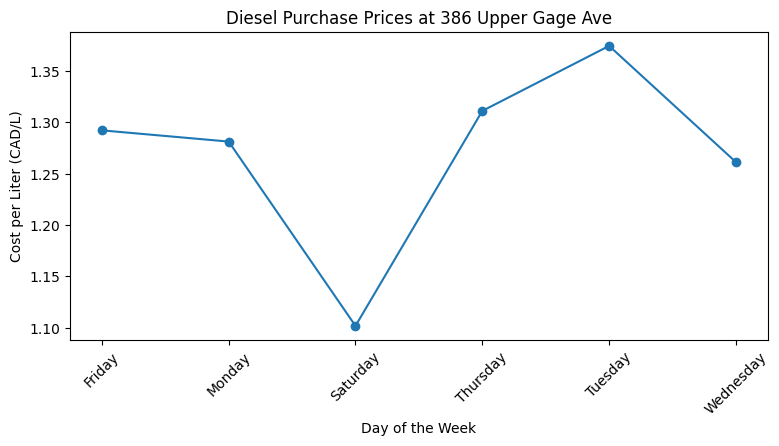

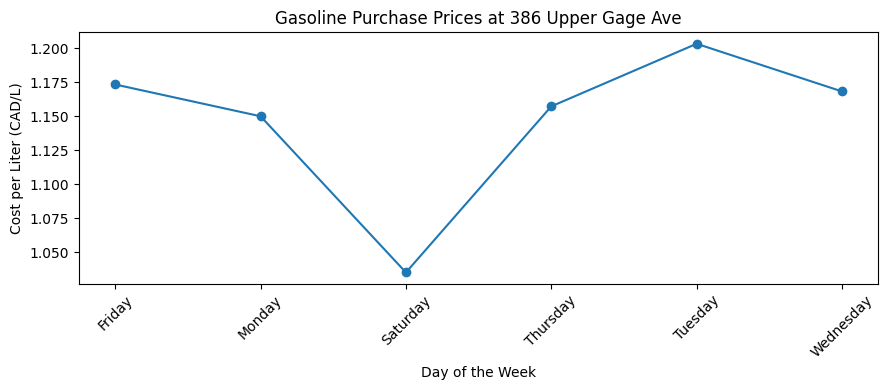

In [17]:
# to control for location, choose one station and compare whether diesel and gas still show the same pattern
invoice_merged[invoice_merged["Gas Station Address"].duplicated()]["Gas Station Address"].value_counts()
# choose the station at 386, which has the most records, and check whether gas and diesel are still cheapest on saturday
only_386 = invoice_merged[invoice_merged["Gas Station Address"] == "386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada"]
only_386_D = only_386[only_386["Fuel Type"]=="D"].groupby("days of the week")["cost per liter"].mean()
only_386_G = only_386[only_386["Fuel Type"]=="G"].groupby("days of the week")["cost per liter"].mean()
print(only_386_D)
print(only_386_G)
fig,ax = plt.subplots(figsize=(9, 4))
ax.plot(only_386_D.index,only_386_D.values,marker="o")
fig,ax2 = plt.subplots(figsize=(9,4))
ax2.plot(only_386_G.index,only_386_G.values,marker="o")
ax.set_title("Diesel Purchase Prices at 386 Upper Gage Ave")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Cost per Liter (CAD/L)")
ax.tick_params(axis="x", rotation=45)
ax2.set_title("Gasoline Purchase Prices at 386 Upper Gage Ave")
ax2.set_xlabel("Day of the Week")
ax2.set_ylabel("Cost per Liter (CAD/L)")
ax2.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
# this station has the same pattern, but one station cannot rule out location effects

In [18]:
# to check the effect of bulk discounts, compare the pattern for purchases above 15000 liters that receive a discount
# then compare the pattern for purchases below 15000 liters that do not receive a discount
# split purchases at the same boundaries used for quantity discounts
# the calculated maximum is 33826, so purchases do not exceed that amount
print(invoice_merged["Amount Purchased"].max())#calculate the maximum of invoice merged
invoice_merged["amount_catagory"] = pd.cut(invoice_merged["Amount Purchased"], bins=[0, 15000, 25000, 40000],
    labels=["small", "medium", "large"], include_lowest=True, right=False)
display(invoice_merged.groupby("amount_catagory", observed=True)["cost per liter"].mean())
# prices also depend on station, fuel type, and purchase date
# but does the discount affect the pattern in the graph?
small_D = invoice_merged[(invoice_merged["Fuel Type"] == "D") & (invoice_merged["amount_catagory"] == "small")].groupby("days of the week")["cost per liter"].mean()
medium_D = invoice_merged[(invoice_merged["Fuel Type"]=="D") & (invoice_merged["amount_catagory"] == "medium")].groupby("days of the week")["cost per liter"].mean()
large1_D = invoice_merged[(invoice_merged["Fuel Type"]=="D") & (invoice_merged["amount_catagory"] == "large")].groupby("days of the week")["cost per liter"].mean()
print(f"S:{small_D}")
print(f"M:{medium_D}")
print(f"L:{large1_D}")# there are no rows with fuel type D in the large group (25000 < amount purchased <= 40000)
small_G = invoice_merged[(invoice_merged["Fuel Type"]=="G") & (invoice_merged["amount_catagory"] == "small")].groupby("days of the week")["cost per liter"].mean()
display(small_G)
# saturday is lowest across these groups, with roughly the same pattern (there are too few medium and large gasoline observations for analysis, so leave them out for now)

33826.56


,cost per liter
amount_catagory,
small,1.222681
medium,1.146653
large,1.086057


S:days of the week
Friday       1.289352
Monday       1.256853
Saturday     1.110370
Thursday     1.255816
Tuesday      1.337469
Wednesday    1.255092
Name: cost per liter, dtype: float64
M:days of the week
Friday       1.063720
Monday       1.099122
Saturday     0.990116
Thursday     1.009739
Tuesday      1.057444
Wednesday    1.121885
Name: cost per liter, dtype: float64
L:Series([], Name: cost per liter, dtype: float64)


,cost per liter
days of the week,
Friday,1.178302
Monday,1.125102
Saturday,1.026616
Thursday,1.135799
Tuesday,1.255506
Wednesday,1.137363


The weekday averages suggest Saturday is cheaper, but station, order size, discounts, and changes in prices over time could affect the result. Compare prices before discounts within the same station, fuel type, and month before drawing a conclusion.

In [19]:
# compare prices before discounts within the same station, fuel type, and month
invoice_merged["price_before_discount"] = invoice_merged["Price_Before_Discount"]
invoice_merged["month"] = invoice_merged["Invoice Date"].dt.to_period("M")
invoice_merged["Saturday"] = invoice_merged["days of the week"] == "Saturday"
weekday_comparison = invoice_merged.pivot_table(
    index=["Invoice Gas Station Location", "Fuel Type", "month"],
    columns="Saturday", values="price_before_discount", aggfunc="mean"
).dropna().rename(columns={False: "Other Days", True: "Saturday"})
weekday_comparison["Difference (CAD/L)"] = (
    weekday_comparison["Other Days"] - weekday_comparison["Saturday"]
)
display(weekday_comparison)
print("Matched station/fuel/month groups:", weekday_comparison.shape[0])
print("Average matched difference (CAD/L):", weekday_comparison["Difference (CAD/L)"].mean())
print("Groups with cheaper Saturday prices:", (weekday_comparison["Difference (CAD/L)"] > 0).sum())
# these are equal-weight group comparisons, not a forecast of savings

Saturday                                        Other Days  Saturday  \
Invoice Gas Station Location Fuel Type month                           
1                            D         2017-03    1.340698  1.352937   
                                       2017-10    0.987224  1.010116   
                                       2018-01    1.050803  1.050802   
                                       2018-02    1.053006  1.060220   
                                       2018-09    1.060220  1.060219   
                                       2018-11    1.094398  1.137387   
                             G         2017-03    1.205194  1.174541   
                                       2017-10    1.033283  1.002917   
                                       2017-11    1.183038  1.098311   
                                       2018-01    1.052039  0.964502   

Saturday                                        Difference (CAD/L)  
Invoice Gas Station Location Fuel Type month                        
1                            D         2017-03       -1.223931e-02  
                                       2017-10       -2.289180e-02  
                                       2018-01        6.305429e-07  
                                       2018-02       -7.214611e-03  
                                       2018-09        9.041408e-07  
                                       2018-11       -4.298913e-02  
                             G         2017-03        3.065318e-02  
                                       2017-10        3.036632e-02  
                                       2017-11        8.472696e-02  
                                       2018-01        8.753651e-02

Matched station/fuel/month groups: 10
Average matched difference (CAD/L): 0.014794965136256366
Groups with cheaper Saturday prices: 6


In [20]:
# check a weekly saturday schedule at average demand
# deliver seven days of fuel each saturday when inventory is at the reserve
weekday_policy = ordering_summary.copy()
weekday_policy["Weekly Order"] = 7 * weekday_policy["Average_Daily_Consumption"]
weekday_policy["Weekly Order Fits"] = (
    weekday_policy["Reserve_Feasible"]
    & (weekday_policy["Weekly Order"] <= weekday_policy["Available_Storage"])
)
display(weekday_policy[["Invoice Gas Station Location", "Fuel Type",
    "Minimum_Reserve", "Weekly Order", "Available_Storage", "Weekly Order Fits"]])
print("Groups where a weekly order fits:", weekday_policy["Weekly Order Fits"].sum())
# this assumes steady demand and an established weekly cycle
# it does not show that historical deliveries could all be moved to saturday
# no additional weekday savings are included in the quantity-discount estimate

,Invoice Gas Station Location,Fuel Type,Minimum_Reserve,Weekly Order,Available_Storage,Weekly Order Fits
0,1,D,53755.398717,53755.398717,26244.601283,False
1,1,G,80897.334844,80897.334844,39102.665156,False
2,2,D,29753.415490,29753.415490,80246.584510,True
3,2,G,22795.513771,22795.513771,87204.486229,True
4,3,D,3282.480903,3282.480903,26717.519097,True
5,3,G,3734.583005,3734.583005,26265.416995,True
6,4,D,15036.801765,15036.801765,24963.198235,True
7,4,G,13643.467164,13643.467164,26356.532836,True
8,5,D,7606.663247,7606.663247,17393.336753,True
9,5,G,11162.884259,11162.884259,13837.115741,True


Groups where a weekly order fits: 14


### Question III — Outcome

Saturday had the lowest overall average price: about CAD 1.095/L for diesel and CAD 1.035/L for gasoline. Compared with Tuesday, these prices are about 17.5% and 14.4% lower. However, there are only 13 Saturday invoices and no Sunday invoices, so the averages alone are not enough to recommend a fixed purchasing day.

After adding back quantity discounts and comparing the same station, fuel type, and month, there are only 10 matched groups, all at Station 1. Saturday is cheaper in six groups, but two differences are nearly zero. The average difference is CAD 0.0148/L across equally weighted groups. Gasoline is cheaper on Saturday in the four matched gasoline groups, while diesel results are mixed. This comparison reduces some differences between purchases, but monthly price changes and the small sample still limit the conclusion.

A weekly delivery of seven days of average demand fits above the reserve for 14 of the 16 station/fuel groups. Neither Station 1 fuel fits that weekly cycle, so both need more frequent deliveries. This assumes steady demand, immediate delivery, and a weekly cycle already in place; it does not recreate historical inventory. Weekly quantities may also earn different discounts from the Question II orders.

Therefore, keep ordering based on the reserve and use Saturday only as a day to consider when price and inventory conditions allow. The data do not establish reliable additional weekday savings, so we do not add any to the Question II estimate.

## Question IV — Tank Replacement

In [21]:
# keep all existing tanks when calculating station capacity
fuel_merged_unique_tank = tanks.drop_duplicates(subset=["Tank ID"]).copy()
fuel_merged_station_capacity = fuel_merged_unique_tank.groupby(
    ["Tank Location", "Tank Type"], as_index=False
)["Tank Capacity"].sum()

# use the reserve already calculated in question 2
minimum_reserve = ordering_summary[[
    "Invoice Gas Station Location", "Fuel Type", "Minimum_Reserve"
]].rename(columns={"Invoice Gas Station Location": "Tank Location",
    "Fuel Type": "Tank Type", "Minimum_Reserve": "Minimum Reserve"})

# each row is one possible tank replacement, not all tanks at once
fuel_merge_Q4 = fuel_merged_unique_tank.loc[
    fuel_merged_unique_tank["Tank Capacity"] < 60000,
    ["Tank ID", "Tank Location", "Tank Type", "Tank Capacity"]
].copy()
fuel_merge_Q4 = pd.merge(fuel_merge_Q4, fuel_merged_station_capacity,
    on=["Tank Location", "Tank Type"], suffixes=("", " Total"))
fuel_merge_Q4 = fuel_merge_Q4.rename(columns={"Tank Capacity Total": "Old Tank Capacity"})
fuel_merge_Q4 = pd.merge(fuel_merge_Q4, minimum_reserve,
    on=["Tank Location", "Tank Type"], how="left")
display(fuel_merge_Q4)

,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve
0,T 10,1,G,40000,120000,80897.334844
1,T 11,1,G,40000,120000,80897.334844
2,T 12,1,D,40000,80000,53755.398717
3,T 14,1,G,40000,120000,80897.334844
4,T 15,1,D,40000,80000,53755.398717
5,T 17,2,D,40000,110000,29753.415490
6,T 18,2,G,40000,110000,22795.513771
7,T 20,3,G,30000,30000,3734.583005
8,T 21,3,D,30000,30000,3282.480903
9,T 22,4,G,40000,40000,13643.467164


available storage = total capacity - 7 day minimum

In [22]:
fuel_merge_Q4["Available Storage"] = fuel_merge_Q4["Old Tank Capacity"]-fuel_merge_Q4["Minimum Reserve"]
display(fuel_merge_Q4)

,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve,Available Storage
0,T 10,1,G,40000,120000,80897.334844,39102.665156
1,T 11,1,G,40000,120000,80897.334844,39102.665156
2,T 12,1,D,40000,80000,53755.398717,26244.601283
3,T 14,1,G,40000,120000,80897.334844,39102.665156
4,T 15,1,D,40000,80000,53755.398717,26244.601283
5,T 17,2,D,40000,110000,29753.415490,80246.584510
6,T 18,2,G,40000,110000,22795.513771,87204.486229
7,T 20,3,G,30000,30000,3734.583005,26265.416995
8,T 21,3,D,30000,30000,3282.480903,26717.519097
9,T 22,4,G,40000,40000,13643.467164,26356.532836


create discount list to show the discount for the forward calculation

In [23]:
discount_list = []
for a in fuel_merge_Q4["Available Storage"]:
  if a >= 40000:
    discount_list.append(0.04)
  elif a >=25000:
    discount_list.append(0.03)
  elif a >=15000:
    discount_list.append(0.02)
  else:
    discount_list.append(0)
print(discount_list)
fuel_merge_Q4["Old Discount Rate"] = discount_list
display(fuel_merge_Q4)


[0.03, 0.03, 0.03, 0.03, 0.03, 0.04, 0.04, 0.03, 0.03, 0.03, 0.02, 0.02, 0, 0.04, 0.04, 0.03, 0, 0, 0.03, 0.03]


,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve,Available Storage,Old Discount Rate
0,T 10,1,G,40000,120000,80897.334844,39102.665156,0.03
1,T 11,1,G,40000,120000,80897.334844,39102.665156,0.03
2,T 12,1,D,40000,80000,53755.398717,26244.601283,0.03
3,T 14,1,G,40000,120000,80897.334844,39102.665156,0.03
4,T 15,1,D,40000,80000,53755.398717,26244.601283,0.03
5,T 17,2,D,40000,110000,29753.415490,80246.584510,0.04
6,T 18,2,G,40000,110000,22795.513771,87204.486229,0.04
7,T 20,3,G,30000,30000,3734.583005,26265.416995,0.03
8,T 21,3,D,30000,30000,3282.480903,26717.519097,0.03
9,T 22,4,G,40000,40000,13643.467164,26356.532836,0.03


Each row represents replacing one tank. Other tanks at that station stay in place, including existing tanks larger than 60,000 liters.

new total capacity = old total capacity - selected tank capacity + 60,000 liters

new available storage = new total capacity - seven-day reserve

In [24]:
# replace only the selected tank with a 60000-liter tank
fuel_merge_Q4["new tank capacity"] = 60000
fuel_merge_Q4["incremental"] = (
    fuel_merge_Q4["new tank capacity"] - fuel_merge_Q4["Tank Capacity"]
)

In [25]:
fuel_merge_Q4["New Tank Capacity"] = fuel_merge_Q4["Old Tank Capacity"] + fuel_merge_Q4["incremental"]
fuel_merge_Q4["New Available Storage"] = fuel_merge_Q4["New Tank Capacity"] - fuel_merge_Q4["Minimum Reserve"]
discount_list_new = []
for a in fuel_merge_Q4["New Available Storage"]:
  if a >= 40000:
    discount_list_new.append(0.04)
  elif a >=25000:
    discount_list_new.append(0.03)
  elif a >=15000:
    discount_list_new.append(0.02)
  else:
    discount_list_new.append(0)
print(discount_list_new)
fuel_merge_Q4["New Discount Rate"] = discount_list_new
display(fuel_merge_Q4)

[0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04]


,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve,Available Storage,Old Discount Rate,new tank capacity,incremental,New Tank Capacity,New Available Storage,New Discount Rate
0,T 10,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04
1,T 11,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04
2,T 12,1,D,40000,80000,53755.398717,26244.601283,0.03,60000,20000,100000,46244.601283,0.04
3,T 14,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04
4,T 15,1,D,40000,80000,53755.398717,26244.601283,0.03,60000,20000,100000,46244.601283,0.04
5,T 17,2,D,40000,110000,29753.415490,80246.584510,0.04,60000,20000,130000,100246.584510,0.04
6,T 18,2,G,40000,110000,22795.513771,87204.486229,0.04,60000,20000,130000,107204.486229,0.04
7,T 20,3,G,30000,30000,3734.583005,26265.416995,0.03,60000,30000,60000,56265.416995,0.04
8,T 21,3,D,30000,30000,3282.480903,26717.519097,0.03,60000,30000,60000,56717.519097,0.04
9,T 22,4,G,40000,40000,13643.467164,26356.532836,0.03,60000,20000,60000,46356.532836,0.04


Compare the best feasible discount with the current capacity against the best feasible discount after replacing one tank. Use the same annualized fuel volume for both. Capacity and reserves are liters, discounts are CAD/L, savings and net benefits are CAD, and payback is years.

In [26]:
# annualize purchases over the full observed invoice period
invoices_merged_amount_purchase = invoice_merged.groupby(
    ["Gas Station Location", "Fuel Type"], as_index=False
)["Amount Purchased"].sum()
invoices_merged_amount_purchase = invoices_merged_amount_purchase.rename(
    columns={"Gas Station Location": "Tank Location", "Fuel Type": "Tank Type"})
one_day = pd.to_datetime("2017-01-02") - pd.to_datetime("2017-01-01")
observed_years = ((invoice_merged["Invoice Date"].max()
    - invoice_merged["Invoice Date"].min()) / one_day + 1) / 365
invoices_merged_amount_purchase["Annual Purchased"] = (
    invoices_merged_amount_purchase["Amount Purchased"] / observed_years
)
fuel_merge_Q4 = pd.merge(fuel_merge_Q4, invoices_merged_amount_purchase,
    on=["Tank Location", "Tank Type"])

# calculate the extra annual discount beyond improved ordering with existing tanks
fuel_merge_Q4["Extra_saving"] = fuel_merge_Q4["Annual Purchased"] * (
    fuel_merge_Q4["New Discount Rate"] - fuel_merge_Q4["Old Discount Rate"]
)
print("Observed invoice years:", observed_years)
display(fuel_merge_Q4)

Observed invoice years: 2.6191780821917807


,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve,Available Storage,Old Discount Rate,new tank capacity,incremental,New Tank Capacity,New Available Storage,New Discount Rate,Amount Purchased,Annual Purchased,Extra_saving
0,T 10,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04,1.086621e+07,4.148710e+06,41487.103492
1,T 11,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04,1.086621e+07,4.148710e+06,41487.103492
2,T 12,1,D,40000,80000,53755.398717,26244.601283,0.03,60000,20000,100000,46244.601283,0.04,4.872458e+06,1.860300e+06,18603.003992
3,T 14,1,G,40000,120000,80897.334844,39102.665156,0.03,60000,20000,140000,59102.665156,0.04,1.086621e+07,4.148710e+06,41487.103492
4,T 15,1,D,40000,80000,53755.398717,26244.601283,0.03,60000,20000,100000,46244.601283,0.04,4.872458e+06,1.860300e+06,18603.003992
5,T 17,2,D,40000,110000,29753.415490,80246.584510,0.04,60000,20000,130000,100246.584510,0.04,3.460900e+06,1.321369e+06,0.000000
6,T 18,2,G,40000,110000,22795.513771,87204.486229,0.04,60000,20000,130000,107204.486229,0.04,2.822514e+06,1.077633e+06,0.000000
7,T 20,3,G,30000,30000,3734.583005,26265.416995,0.03,60000,30000,60000,56265.416995,0.04,4.235187e+05,1.616991e+05,1616.990685
8,T 21,3,D,30000,30000,3282.480903,26717.519097,0.03,60000,30000,60000,56717.519097,0.04,4.318151e+05,1.648667e+05,1648.666515
9,T 22,4,G,40000,40000,13643.467164,26356.532836,0.03,60000,20000,60000,46356.532836,0.04,1.578618e+06,6.027149e+05,6027.149459


Project the annual extra savings over five years and subtract the cost of one replacement. Compare cost and demand scenarios and calculate simple payback.

In [27]:
# calculate five-year savings and the cost of one replacement
fuel_merge_Q4["5 Years Saving"] = fuel_merge_Q4["Extra_saving"] * 5
fuel_merge_Q4["Profit"] = fuel_merge_Q4["5 Years Saving"] - 250000
fuel_merge_Q4["Payback Years"] = float("inf")
fuel_merge_Q4.loc[fuel_merge_Q4["Extra_saving"] > 0, "Payback Years"] = (
    250000 / fuel_merge_Q4.loc[fuel_merge_Q4["Extra_saving"] > 0, "Extra_saving"]
)
display(fuel_merge_Q4[["Tank ID", "Tank Location", "Tank Type", "Old Discount Rate",
    "New Discount Rate", "Extra_saving", "5 Years Saving", "Profit", "Payback Years"]].round(2))
display(fuel_merge_Q4.loc[fuel_merge_Q4["Profit"] > 0])

# check lower and higher replacement costs and demand
replacement_scenarios = []
for cost in [150000, 250000, 350000]:
    for demand in [0.8, 1.0, 1.2]:
        scenario = fuel_merge_Q4[["Tank ID", "Tank Location", "Tank Type",
            "Old Tank Capacity", "New Tank Capacity", "Minimum Reserve", "Annual Purchased"]].copy()
        scenario["Replacement Cost"] = cost
        scenario["Demand Multiplier"] = demand
        scenario["Scenario Reserve"] = scenario["Minimum Reserve"] * demand
        scenario["Old Storage"] = scenario["Old Tank Capacity"] - scenario["Scenario Reserve"]
        scenario["New Storage"] = scenario["New Tank Capacity"] - scenario["Scenario Reserve"]
        for storage, discount in [("Old Storage", "Old Discount"), ("New Storage", "New Discount")]:
            scenario[discount] = 0.00
            scenario.loc[scenario[storage] >= 15000, discount] = 0.02
            scenario.loc[scenario[storage] >= 25000, discount] = 0.03
            scenario.loc[scenario[storage] >= 40000, discount] = 0.04
        scenario["Reserve Feasible"] = (scenario["Old Storage"] > 0) & (scenario["New Storage"] > 0)
        scenario["Annual Extra Saving"] = scenario["Annual Purchased"] * demand * (
            scenario["New Discount"] - scenario["Old Discount"])
        scenario["Five-Year Net Benefit"] = scenario["Annual Extra Saving"] * 5 - cost
        replacement_scenarios.append(scenario)
replacement_scenarios = pd.concat(replacement_scenarios, ignore_index=True)
display(replacement_scenarios)
display(replacement_scenarios.sort_values("Five-Year Net Benefit", ascending=False).groupby(
    ["Replacement Cost", "Demand Multiplier"]
).head(1)[["Replacement Cost", "Demand Multiplier", "Tank ID", "Tank Location",
    "Tank Type", "Reserve Feasible", "Five-Year Net Benefit"]].sort_values(
    ["Replacement Cost", "Demand Multiplier"]).round(2))
# different tanks at the same station are alternative investments, not savings to add together

,Tank ID,Tank Location,Tank Type,Old Discount Rate,New Discount Rate,Extra_saving,5 Years Saving,Profit,Payback Years
0,T 10,1,G,0.03,0.04,41487.10,207435.52,-42564.48,6.03
1,T 11,1,G,0.03,0.04,41487.10,207435.52,-42564.48,6.03
2,T 12,1,D,0.03,0.04,18603.00,93015.02,-156984.98,13.44
3,T 14,1,G,0.03,0.04,41487.10,207435.52,-42564.48,6.03
4,T 15,1,D,0.03,0.04,18603.00,93015.02,-156984.98,13.44
5,T 17,2,D,0.04,0.04,0.00,0.00,-250000.00,inf
6,T 18,2,G,0.04,0.04,0.00,0.00,-250000.00,inf
7,T 20,3,G,0.03,0.04,1616.99,8084.95,-241915.05,154.61
8,T 21,3,D,0.03,0.04,1648.67,8243.33,-241756.67,151.64
9,T 22,4,G,0.03,0.04,6027.15,30135.75,-219864.25,41.48


,Tank ID,Tank Location,Tank Type,Tank Capacity,Old Tank Capacity,Minimum Reserve,Available Storage,Old Discount Rate,new tank capacity,incremental,New Tank Capacity,New Available Storage,New Discount Rate,Amount Purchased,Annual Purchased,Extra_saving,5 Years Saving,Profit,Payback Years


,Tank ID,Tank Location,Tank Type,Old Tank Capacity,New Tank Capacity,Minimum Reserve,Annual Purchased,Replacement Cost,Demand Multiplier,Scenario Reserve,Old Storage,New Storage,Old Discount,New Discount,Reserve Feasible,Annual Extra Saving,Five-Year Net Benefit
0,T 10,1,G,120000,140000,80897.334844,4.148710e+06,150000,0.8,64717.867875,55282.132125,75282.132125,0.04,0.04,True,0.000000,-150000.000000
1,T 11,1,G,120000,140000,80897.334844,4.148710e+06,150000,0.8,64717.867875,55282.132125,75282.132125,0.04,0.04,True,0.000000,-150000.000000
2,T 12,1,D,80000,100000,53755.398717,1.860300e+06,150000,0.8,43004.318974,36995.681026,56995.681026,0.03,0.04,True,14882.403194,-75587.984030
3,T 14,1,G,120000,140000,80897.334844,4.148710e+06,150000,0.8,64717.867875,55282.132125,75282.132125,0.04,0.04,True,0.000000,-150000.000000
4,T 15,1,D,80000,100000,53755.398717,1.860300e+06,150000,0.8,43004.318974,36995.681026,56995.681026,0.03,0.04,True,14882.403194,-75587.984030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,T 28,6,D,30000,60000,511.388536,2.085767e+04,350000,1.2,613.666243,29386.333757,59386.333757,0.03,0.04,True,250.292039,-348748.539803
176,T 29,7,G,5000,60000,917.138251,3.572220e+04,350000,1.2,1100.565901,3899.434099,58899.434099,0.00,0.04,True,1714.665833,-341426.670835
177,T 30,7,D,5000,60000,128.798302,4.231202e+03,350000,1.2,154.557963,4845.442037,59845.442037,0.00,0.04,True,203.097704,-348984.511478
178,T 31,8,D,40000,60000,643.269343,2.903614e+04,350000,1.2,771.923212,39228.076788,59228.076788,0.03,0.04,True,348.433728,-348257.831359


,Replacement Cost,Demand Multiplier,Tank ID,Tank Location,Tank Type,Reserve Feasible,Five-Year Net Benefit
2,150000,0.8,T 12,1,D,True,-75587.98
23,150000,1.0,T 14,1,G,True,57435.52
40,150000,1.2,T 10,1,G,True,347845.24
62,250000,0.8,T 12,1,D,True,-175587.98
80,250000,1.0,T 10,1,G,True,-42564.48
103,250000,1.2,T 14,1,G,True,247845.24
122,350000,0.8,T 12,1,D,True,-275587.98
143,350000,1.0,T 14,1,G,True,-142564.48
160,350000,1.2,T 10,1,G,True,147845.24


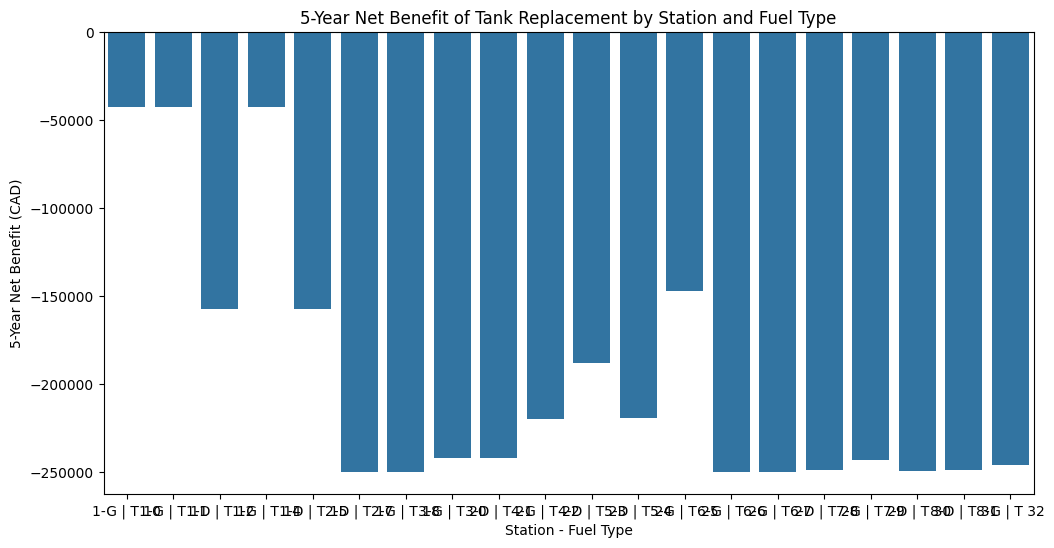

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
plt.figure(figsize=(12, 6))

# Create label: 1-D, 1-G, 2-D, 2-G...
fuel_merge_Q4["Station_Fuel"] = (
    fuel_merge_Q4["Tank Location"].astype(str)
    + "-"
    + fuel_merge_Q4["Tank Type"]
    + " | " + fuel_merge_Q4["Tank ID"]
)

sns.barplot(
    data=fuel_merge_Q4,
    x="Station_Fuel",
    y="Profit"
)

# Break-even line
plt.axhline(y=0, linestyle="--")

plt.xlabel("Station - Fuel Type")
plt.ylabel("5-Year Net Benefit (CAD)")
plt.title("5-Year Net Benefit of Tank Replacement by Station and Fuel Type")

plt.show()

In [29]:
import pandas as pd
import plotly.express as px

station_profit = (
    fuel_merge_Q4
    .groupby("Tank Location")["Profit"]
    .max()
    .reset_index()
)


station_profit = station_profit.rename(
    columns={"Tank Location": "Gas Station Location"}
)


map_data = pd.merge(
    locations,
    station_profit,
    on="Gas Station Location",
    how="left"
)


map_data["Replacement Result"] = map_data["Profit"].apply(
    lambda x: "Profitable" if x > 0 else "Not Profitable"
)

fig = px.scatter_map(
    map_data,
    lat="Gas Station Latitude",
    lon="Gas Station Longitude",
    color="Replacement Result",
    hover_name="Gas Station Location",
    hover_data={"Profit": ":,.2f"},
    zoom=5,
    title="Best Single-Tank Replacement Result by Station (CAD)"
)

fig.update_traces(marker={"size": 18})

fig.show()

### Question IV — Outcome

At a replacement cost of CAD 250,000, none of the single-tank replacements produces a positive five-year net benefit. The strongest case is Station 1 gasoline: replacing one 40,000-liter tank with a 60,000-liter tank raises total gasoline capacity from 120,000 to 140,000 liters. Available storage at the reserve then allows the discount to increase from CAD 0.03/L to CAD 0.04/L.

Using annualized purchases, this gives about CAD 41,487 in additional savings per year and CAD 207,436 over five years. The five-year net benefit is approximately negative CAD 42,564, with simple payback of 6.03 years. T 10, T 11, and T 14 are equivalent alternatives for this calculation; their savings should not be added together. Station 2 already has enough total storage for the highest discount under improved ordering, so replacement adds no quantity-discount benefit there.

Replacement cost and demand change the decision. At current demand and a CAD 150,000 cost, the Station 1 gasoline alternatives produce about CAD 57,436 in five-year net benefits. At CAD 350,000, none is profitable at current demand. With demand 20% higher, a single Station 1 gasoline replacement produces about CAD 247,845 in five-year net benefits at the CAD 250,000 cost. This larger gain occurs because the higher reserve lowers the existing tanks' attainable discount to CAD 0.02/L, while replacement restores CAD 0.04/L. With demand 20% lower, none of the replacements is profitable at any tested cost.

Therefore, improve ordering first rather than replacing a tank at the baseline cost and demand. Reconsider Station 1 gasoline if replacement costs fall or demand grows enough to change the discount threshold.

### Limitations


First, our tank replacement analysis is a relatively rough estimation. We use historical average demand, available tank capacity, quantity discounts, and replacement costs to estimate annual savings and five-year net benefits. In reality, fuel demand, purchase prices, order quantities, and operating costs may change over time. Therefore, our results should be viewed as an approximate financial evaluation rather than an exact prediction of future savings.

Second, the actual replacement decision should be analyzed on a case-by-case basis. Each station and tank may have different demand levels, storage conditions, installation costs, and operational requirements. A tank that appears profitable under our model may face additional costs or physical constraints in practice. Therefore, the model can help identify potentially attractive replacement opportunities, but each candidate should be evaluated individually before making the final investment decision.